In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
import pickle
import scanpy as sc
import seaborn as sns
import csv
import os 

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# overview all datasets 

In [2]:
import pickle
import os
import pandas as pd

# ------------------------------------------------------------
# Preprocessed datasets (cell × gene matrices)
# ------------------------------------------------------------
file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl",

        "morris_rna":  "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/morris_RNA.pkl",
    "morris_atac": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/morris_ATAC.pkl",
}

# ------------------------------------------------------------
# Count cells
# ------------------------------------------------------------
print("\n================ CELL COUNTS (preprocessing PKLs) ================\n")

for name, path in file_dict.items():
    if not os.path.exists(path):
        print(f"{name:20s}  ->  MISSING FILE")
        continue

    with open(path, "rb") as f:
        df = pickle.load(f)

    # Preprocessing PKLs are cell × gene
    n_cells = df.shape[0]
    n_genes = df.shape[1]

    print(f"{name:20s}  ->  {n_cells:6d} cells   |   {n_genes:6d} genes")

print("\n==================================================================\n")



================ CELL COUNTS (preprocessing PKLs) ================

weinreb               ->   49302 cells   |    22637 genes
treutlein             ->   16506 cells   |    20857 genes
junker                ->    6191 cells   |    21063 genes
knoblich_day16_1      ->    5695 cells   |    29316 genes
knoblich_day16_2      ->    8730 cells   |    28919 genes
knoblich_day42_1      ->    9533 cells   |    29000 genes
knoblich_day42_2      ->    8109 cells   |    29049 genes
you1                  ->   18650 cells   |    25350 genes
you2                  ->   42640 cells   |    26855 genes
you3                  ->   23883 cells   |    25991 genes
you4                  ->    2864 cells   |    23287 genes
morris_rna            ->     851 cells   |    13047 genes
morris_atac           ->    1892 cells   |   163647 genes




# export all genes as rnk files 

In [10]:
import pickle
import os
import pandas as pd
from typing import Dict   
import csv  # Needed for csv.DictReader

def read_csv_as_dict(file_path, key_column='Mouse Gene', value_column='Human Gene'): #col called mouse gene falsly but is in fact fish genes
    result_dict = {}
    
    with open(file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        for row in csv_reader:
            result_dict[row[key_column]] = row[value_column]
    
    return result_dict

fish_to_human_dic = read_csv_as_dict('/fast/AG_Metzger/philipp/python_files/gene_signature/fish_to_human_dic.csv')

from scipy.stats import rankdata

def export_rnk_files(dataframes: Dict[str, pd.DataFrame], output_dir: str):
    os.makedirs(output_dir, exist_ok=True)

    for name, df in dataframes.items():
        if name == "junker":
            mapped_index = df["gene"].map(fish_to_human_dic)
            valid_mask = mapped_index.notna()
            df = df.loc[valid_mask].copy()
            df["gene"] = df["gene"].map(fish_to_human_dic)
            df = df[df["gene"] != ""]

        # Filter on MI > permutation
        #df = df.loc[df["true_mi"] > df["95_perm_mi"]]
        print(df.shape)
        df = df.loc[df["true_mi"] != 0]
        print(df.shape)

        # Apply ranking
        print(df)
        df_sorted = df[["gene", "normalized_MI_label_entropy"]].sort_values(by="normalized_MI_label_entropy", ascending=False)
        
        rnk_path = os.path.join(output_dir, f"{name}.rnk")
        df_sorted.to_csv(rnk_path, sep='\t', header=False, index=False)
        print(f"Saved: {rnk_path}")


# Unified base path
base_path = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel"

dataframes = {
    "knoblich_day16_1": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day16_1_50_permutations.csv"),
    "knoblich_day16_2": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day16_2_50_permutations.csv"),
    "knoblich_day42_1": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day42_1_50_permutations.csv"),
    "knoblich_day42_2": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day42_2_50_permutations.csv"),

    "weinreb": pd.read_csv(f"{base_path}/MI_label_entropy_weinreb_50_permutations.csv"),
    "treutlein": pd.read_csv(f"{base_path}/MI_label_entropy_treutlein_50_permutations.csv"),
    "junker": pd.read_csv(f"{base_path}/MI_label_entropy_junker_50_permutations.csv"),

    "you1": pd.read_csv(f"{base_path}/MI_label_entropy_you1_50_permutations.csv"),
    "you2": pd.read_csv(f"{base_path}/MI_label_entropy_you2_50_permutations.csv"),
    "you3": pd.read_csv(f"{base_path}/MI_label_entropy_you3_50_permutations.csv"),
    "you4": pd.read_csv(f"{base_path}/MI_label_entropy_you4_50_permutations.csv"),
}


export_rnk_files(dataframes, 'rnk_files_all_genes_div_by_entropy_non_zero/')


(29315, 6)
(29315, 6)
              gene   true_mi  mean_perm_mi  95_perm_mi  std_perm_mi  \
0      MIR1302-2HG  0.003112      0.003475    0.004600     0.000652   
1       AL627309.1  0.027443      0.030501    0.035431     0.002838   
2       AL627309.5  0.045544      0.042004    0.049704     0.003962   
3       AL627309.4  0.011336      0.010996    0.013093     0.001346   
4       AP006222.2  0.007448      0.006948    0.008840     0.001126   
...            ...       ...           ...         ...          ...   
29310   AC240274.1  0.095841      0.102964    0.110110     0.005055   
29311   AC004556.3  0.049374      0.051881    0.057447     0.003769   
29312   AC136352.3  0.002066      0.001814    0.002794     0.000543   
29313   AC007325.4  0.040855      0.039886    0.044759     0.002980   
29314   AC007325.2  0.011668      0.010794    0.012673     0.001382   

       normalized_MI_label_entropy  
0                         0.000624  
1                         0.005507  
2             

Saved: rnk_files_all_genes_div_by_entropy_non_zero/you2.rnk
(25990, 6)
(25990, 6)
                gene   true_mi  mean_perm_mi  95_perm_mi  std_perm_mi  \
0       RP11-34P13.3  0.012949      0.013311    0.014082     0.000452   
1       RP11-34P13.7  0.032062      0.031805    0.033028     0.000719   
2         FO538757.2  1.197642      1.164560    1.172021     0.004652   
3         AP006222.2  1.411038      1.370983    1.379588     0.004957   
4      RP4-669L17.10  0.054964      0.056035    0.057963     0.001188   
...              ...       ...           ...         ...          ...   
25985      KRTAP19-7  0.001203      0.001134    0.001339     0.000123   
25986          DSCR8  0.001507      0.001686    0.001924     0.000172   
25987     AL773572.7  0.002748      0.003285    0.003619     0.000218   
25988      KRTAP10-2  0.001924      0.001766    0.002008     0.000172   
25989     AP001471.1  0.002008      0.001794    0.002008     0.000131   

       normalized_MI_label_entropy  
0   

# exporting IG NN scores as rnk files 

In [7]:
import os
import pandas as pd
import csv
from typing import Dict

# --- Load fish-to-human gene mapping ---
def read_csv_as_dict(file_path, key_column='Mouse Gene', value_column='Human Gene'):
    result_dict = {}
    with open(file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        for row in csv_reader:
            result_dict[row[key_column]] = row[value_column]
    return result_dict

fish_to_human_dic = read_csv_as_dict('/fast/AG_Metzger/philipp/python_files/gene_signature/fish_to_human_dic.csv')

def export_ig_rnk_files(ig_files: Dict[str, str], output_dir: str):
    os.makedirs(output_dir, exist_ok=True)

    for name, path in ig_files.items():
        df = pd.read_csv(path)

        # Keep only the accumulated-score rows (barcode_cont == -1)
        df = df[df["barcode_cont"] == -1].copy()

        # Use absolute score as ranking metric
        df["absolute score"] = df["score"].abs()

        # Drop exact zeros (no contribution to ranking)
        df = df[df["absolute score"] > 0]

        # Map zebrafish to human gene names for junker
        if name == "junker":
            mapped_genes = df["gene"].map(fish_to_human_dic)
            valid_mask = mapped_genes.notna() & (mapped_genes != "")
            df = df[valid_mask].copy()
            df["gene"] = mapped_genes[valid_mask]

            # Collapse duplicates: keep max absolute score per human gene
            df = (
                df.groupby("gene", as_index=False)["absolute score"]
                  .max()
            )
        else:
            # Just in case there are duplicated gene names: keep max score
            df = (
                df.groupby("gene", as_index=False)["absolute score"]
                  .max()
            )

        # Sort by absolute score (descending) and export
        df = df.sort_values("absolute score", ascending=False).reset_index(drop=True)#.head(2000)
        print(name, df.shape)

        rnk_path = os.path.join(output_dir, f"{name}_ig.rnk")
        df[["gene", "absolute score"]].to_csv(
            rnk_path,
            sep="\t",
            header=False,
            index=False,
        )
        print(f"Saved: {rnk_path}")


In [5]:
ig_file_paths = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/NN/weinreb_all_genes_integrated_gradient.csv",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/NN/treutlein_all_genes_integrated_gradient.csv"}

In [8]:
export_ig_rnk_files(ig_file_paths, 'rnk_files_integrated_gradient/')

weinreb (11535, 2)
Saved: rnk_files_integrated_gradient/weinreb_ig.rnk
treutlein (15498, 2)
Saved: rnk_files_integrated_gradient/treutlein_ig.rnk


In [6]:
export_ig_rnk_files(ig_file_paths, 'rnk_files_integrated_gradient/')

weinreb (22636, 2)
Saved: rnk_files_integrated_gradient_also_0/weinreb_ig.rnk
treutlein (20856, 2)
Saved: rnk_files_integrated_gradient_also_0/treutlein_ig.rnk


## Expression per lineage Plots

In [2]:
import pandas as pd

BASE = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel"

normalized_MI_junker = pd.read_csv(f"{BASE}/MI_label_entropy_junker_50_permutations.csv")
normalized_MI_knoblich_day16_1 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day16_1_50_permutations.csv")
normalized_MI_knoblich_day16_2 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day16_2_50_permutations.csv")
normalized_MI_knoblich_day42_1 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day42_1_50_permutations.csv")
normalized_MI_knoblich_day42_2 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day42_2_50_permutations.csv")

normalized_MI_treutlein = pd.read_csv(f"{BASE}/MI_label_entropy_treutlein_50_permutations.csv")
normalized_MI_weinreb = pd.read_csv(f"{BASE}/MI_label_entropy_weinreb_50_permutations.csv")

normalized_MI_you1 = pd.read_csv(f"{BASE}/MI_label_entropy_you1_50_permutations.csv")
normalized_MI_you2 = pd.read_csv(f"{BASE}/MI_label_entropy_you2_50_permutations.csv")
normalized_MI_you3 = pd.read_csv(f"{BASE}/MI_label_entropy_you3_50_permutations.csv")
normalized_MI_you4 = pd.read_csv(f"{BASE}/MI_label_entropy_you4_50_permutations.csv")

# Assign dataset names for the legend
dfs = [
    (normalized_MI_you1, 'HBO3_1'),
    (normalized_MI_you2, 'HBO3_2'),
    (normalized_MI_you3, 'HBO3_3'),
    (normalized_MI_you4, 'HBO3_4'),
    (normalized_MI_knoblich_day16_1, 'HBO2_16_1'),
    (normalized_MI_knoblich_day16_2, 'HBO2_16_2'),
    (normalized_MI_knoblich_day42_1, 'HBO2_42_1'),
    (normalized_MI_knoblich_day42_2, 'HBO2_42_2'),
    (normalized_MI_treutlein, 'HBO1'),
    (normalized_MI_weinreb, 'MHPSC'),
    (normalized_MI_junker, 'ZFL')
]


# Add a 'dataset' column to each dataframe
for df, name in dfs:
    df['dataset'] = name

# Concatenate all dataframes together
all_data = pd.concat([df for df, name in dfs], ignore_index=True)

file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl"
}

In [3]:
from typing import Optional
import os
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def load_expression_df(dataset_key: str, file_dict: dict) -> pd.DataFrame:
    pkl_path = file_dict[dataset_key]
    with open(pkl_path, "rb") as f:
        obj = pickle.load(f)
    if not isinstance(obj, pd.DataFrame):
        raise TypeError(f"Unsupported pkl content type: {type(obj)} (expected pandas.DataFrame)")
    if "barcode_cont" not in obj.columns:
        raise ValueError(f"'barcode_cont' column missing in {pkl_path}")
    return obj


def order_along_mean_expression(df: pd.DataFrame, genename: str, group_col: str = "barcode_cont"):
    mean_by_bc = df.groupby(group_col, observed=True)[genename].mean()
    return mean_by_bc.sort_values(ascending=True).index.to_list()


def plot_boxplot_1_gene_across_lineages(
    dataset_key: str,
    genename: str,
    file_dict: dict,
    filename: str,
    mi_df: Optional[pd.DataFrame] = None,
    mi_value_col: str = "normalized_MI_label_entropy",
    gene_col: str = "gene",
    out_dir: str = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/",
    min_no_of_cells_per_lineage: int = 20,
    color: str = "blue",
    group_col: str = "barcode_cont",
    y_label: Optional[str] = None,
    title: Optional[str] = None,
    mi_decimals: int = 4,
):
    """
    Same as before, but if `mi_df` is provided, the plot title will include:
      normalized MI value for `genename` from `mi_df[mi_value_col]`.
    """
    palettes = {"blue": "#ADD8E6", "green": "#90EE90", "orange": "#FFA07A"}
    if color not in palettes:
        raise ValueError(f"color must be one of {list(palettes.keys())}, got '{color}'")

    df = load_expression_df(dataset_key, file_dict)

    if genename not in df.columns:
        raise KeyError(f"Gene '{genename}' not found in dataset '{dataset_key}'.")

    df = df.copy()
    df[genename] = pd.to_numeric(df[genename], errors="coerce")

    # lineage-size filter
    counts = df[group_col].value_counts()
    df["barcode frequency"] = df[group_col].map(counts)
    df = df.loc[df["barcode frequency"] > min_no_of_cells_per_lineage].copy()
    if df.empty:
        raise ValueError(
            f"No data left after min_no_of_cells_per_lineage filter "
            f"(dataset={dataset_key}, gene={genename}, min={min_no_of_cells_per_lineage})."
        )

    # q75>0 filter
    q75 = df.groupby(group_col, observed=True)[genename].quantile(0.75)
    barcodes_to_consider = q75[q75 > 0].index
    df = df.loc[df[group_col].isin(barcodes_to_consider)].copy()
    if df.empty:
        raise ValueError(f"No data left after q75>0 filter (dataset={dataset_key}, gene={genename}).")

    custom_order = order_along_mean_expression(df, genename, group_col=group_col)

    # fetch MI value (optional)
    mi_val = None
    if mi_df is not None:
        if gene_col not in mi_df.columns or mi_value_col not in mi_df.columns:
            raise KeyError(f"mi_df must contain columns '{gene_col}' and '{mi_value_col}'.")
        hits = mi_df.loc[mi_df[gene_col] == genename, mi_value_col]
        if len(hits) > 0:
            # if duplicated genes exist, take the max (safest)
            mi_val = float(hits.max())

    # build title
    if title is None:
        if mi_val is None:
            plot_title = f"{genename} ({dataset_key})"
        else:
            plot_title = f"{genename} ({dataset_key}) — {mi_value_col}={mi_val:.{mi_decimals}f}"
    else:
        # if user passes title, append MI if available
        if mi_val is None:
            plot_title = title
        else:
            plot_title = f"{title} — {mi_value_col}={mi_val:.{mi_decimals}f}"

    # plot
    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, filename)

    plt.figure(figsize=(12, 6))
    flier_marker = dict(marker=".", color=palettes[color], markersize=2, linestyle="none")

    sns.boxplot(
        data=df,
        y=genename,
        x=group_col,
        order=custom_order,
        color=palettes[color],
        flierprops=flier_marker,
        linewidth=0.5,
    )
    sns.despine()
    plt.xlabel("")
    plt.ylabel(y_label if y_label is not None else f"Expression {genename}")
    plt.title(plot_title)
    plt.xticks([])
    plt.tight_layout()
    plt.savefig(out_path)
    plt.show()
    plt.close()

    return barcodes_to_consider, custom_order, df, mi_val


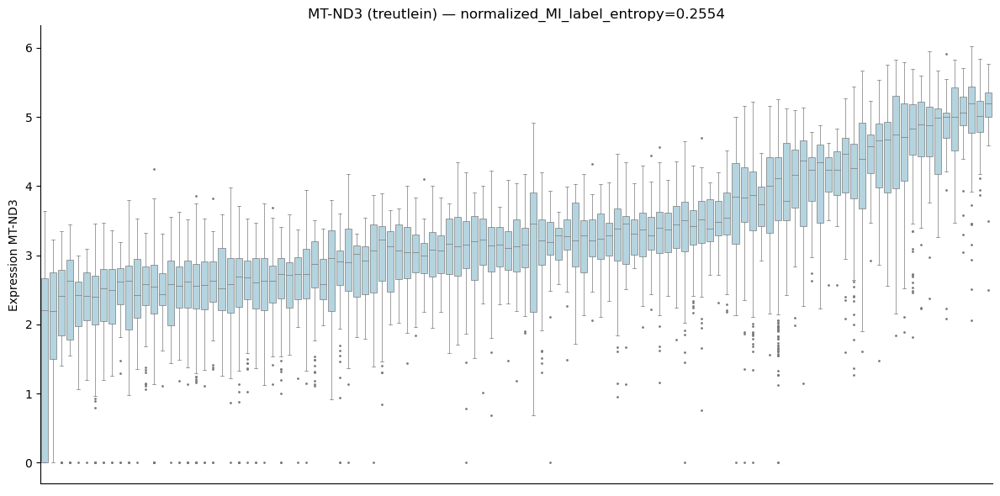

MI value used: 0.2553778528760417


In [4]:
top_mi_gene_treutlein = (
    normalized_MI_treutlein
    .sort_values("normalized_MI_label_entropy", ascending=False)
    .iloc[0]["gene"]
)

barcodes, order, df_used, mi_val = plot_boxplot_1_gene_across_lineages(
    dataset_key="treutlein",
    genename=top_mi_gene_treutlein,
    file_dict=file_dict,
    mi_df=normalized_MI_treutlein,
    filename=f"treutlein_{top_mi_gene_treutlein}_expression_boxplot.pdf",
    color="blue",
)
print("MI value used:", mi_val)


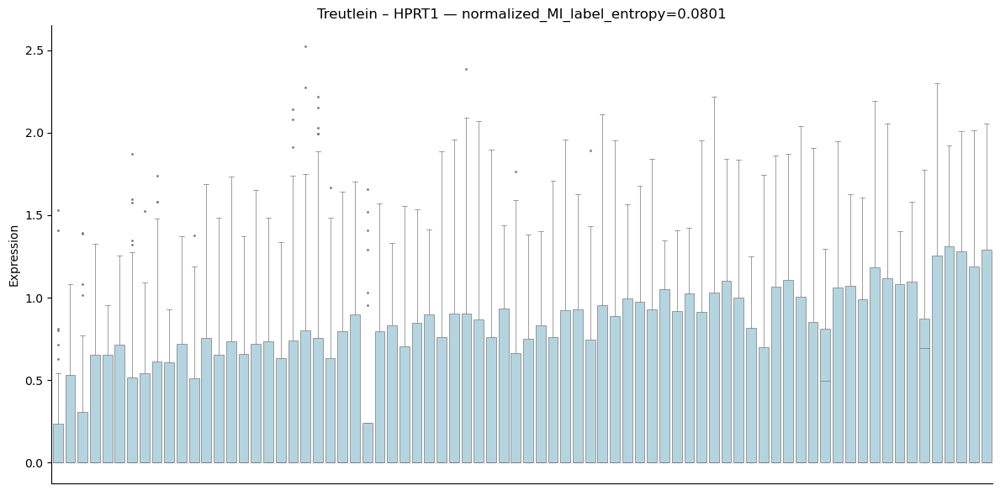

Normalized MI (label entropy): 0.0801072671029294


In [5]:
barcodes, order, df_used, mi_val = plot_boxplot_1_gene_across_lineages(
    dataset_key="treutlein",
    genename="HPRT1",
    file_dict=file_dict,
    mi_df=normalized_MI_treutlein,   # <-- NEW
    filename="treutlein_HPRT1_expression_boxplot.pdf",
    min_no_of_cells_per_lineage=20,
    color="blue",
    y_label="Expression",
    title="Treutlein – HPRT1"
)

print("Normalized MI (label entropy):", mi_val)


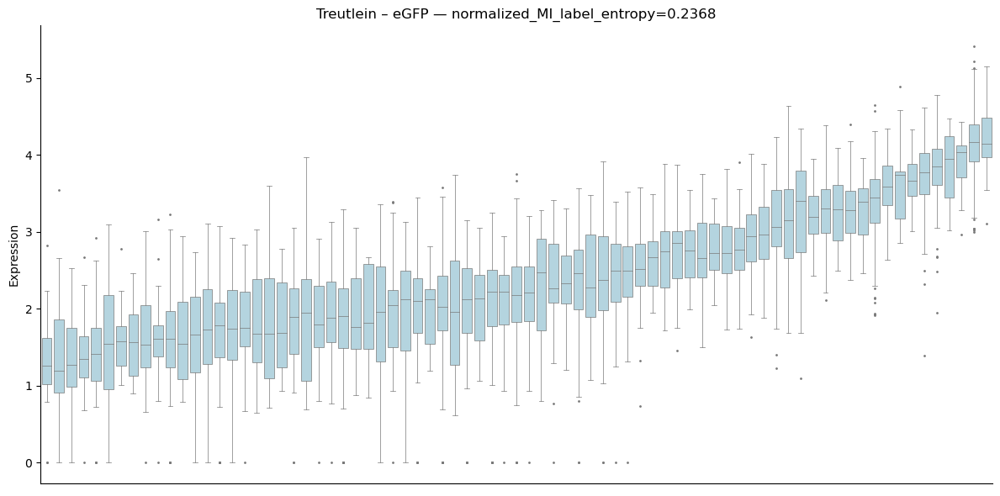

Normalized MI (label entropy): 0.2367890219437038


In [6]:
barcodes, order, df_used, mi_val = plot_boxplot_1_gene_across_lineages(
    dataset_key="treutlein",
    genename="eGFP",
    file_dict=file_dict,
    mi_df=normalized_MI_treutlein,   # <-- NEW
    filename="treutlein_eGFP_expression_boxplot.pdf",
    min_no_of_cells_per_lineage=20,
    color="blue",
    y_label="Expression",
    title="Treutlein – eGFP"
)

print("Normalized MI (label entropy):", mi_val)


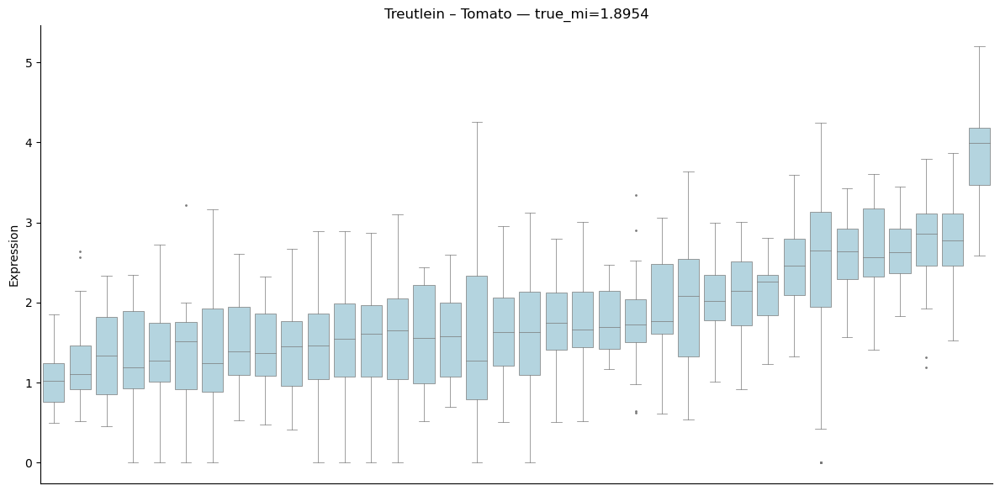

Normalized MI (label entropy): 1.895432978381529


In [7]:
barcodes, order, df_used, mi_val = plot_boxplot_1_gene_across_lineages(
    dataset_key="treutlein",
    genename="Tomato",
    file_dict=file_dict,
    mi_df=normalized_MI_treutlein,   # <-- NEW
    filename="treutlein_tomato_expression_boxplot.pdf",
    min_no_of_cells_per_lineage=20,
    color="blue",
    y_label="Expression",
    title="Treutlein – Tomato"
)

print("Normalized MI (label entropy):", mi_val)

# Plotting Integrated Gradients vs normalized Mutual Information

In [8]:
import pandas as pd

BASE = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel"

normalized_MI_treutlein = pd.read_csv(f"{BASE}/MI_label_entropy_treutlein_50_permutations.csv")
normalized_MI_weinreb = pd.read_csv(f"{BASE}/MI_label_entropy_weinreb_50_permutations.csv")

In [9]:
# importing integrated gradient data
import pandas as pd

integrated_gradients_weinreb = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/NN/weinreb_all_genes_integrated_gradient.csv")
integrated_gradients_treutlein = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/NN/treutlein_all_genes_integrated_gradient.csv")



In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr


def prepare_ig_accumulated(
    ig_df: pd.DataFrame,
    gene_col: str = "gene",
    score_col: str = "score",
    barcode_col: str = "barcode_cont",
    accumulated_value: int = -1,
) -> pd.DataFrame:
    """
    Canonical IG preprocessing:
      1) keep only accumulated IG rows (barcode_cont == -1)
      2) take absolute score
      3) collapse to ONE value per gene (max |IG| if duplicates exist)
    Returns a DF indexed by gene with column: 'absolute_score'
    """
    ig_acc = ig_df.loc[ig_df[barcode_col] == accumulated_value, [gene_col, score_col]].copy()
    ig_acc["absolute_score"] = ig_acc[score_col].abs()

    ig_acc = (
        ig_acc.dropna(subset=[gene_col, "absolute_score"])
              .groupby(gene_col, as_index=True)["absolute_score"]
              .max()
              .to_frame()
    )
    return ig_acc


def plot_ig_vs_mi_all_genes(
    mi_df: pd.DataFrame,
    ig_df: pd.DataFrame,
    dataset_name: str = None,               # for filename (optional)
    dataset_label: str = None,              # printed on plot (optional)
    out_dir: str = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/",
    mi_col: str = "normalized_MI_label_entropy",
    mi_gene_col: str = "gene",
    ig_gene_col: str = "gene",
    ig_score_col: str = "score",
    ig_barcode_col: str = "barcode_cont",
    ig_accumulated_barcode_value: int = -1,
    figsize: tuple = (10.5, 7.0),
    save: bool = True,
):
    """
    Style matched to plot_lime_vs_integrated_gradient():
      - matplotlib-only scatter
      - no grid
      - axes start at (0,0)
      - hide top/right spines
      - correlation annotation in axes coords
      - optional dataset_label text
      - PDF export to out_dir
    """
    os.makedirs(out_dir, exist_ok=True)

    # ----------------------------
    # Prepare MI
    # ----------------------------
    if mi_gene_col not in mi_df.columns or mi_col not in mi_df.columns:
        raise KeyError(f"mi_df must contain columns '{mi_gene_col}' and '{mi_col}'")

    mi_use = (
        mi_df[[mi_gene_col, mi_col]]
        .dropna(subset=[mi_gene_col, mi_col])
        .drop_duplicates(subset=[mi_gene_col])
        .set_index(mi_gene_col)
    )

    # ----------------------------
    # Prepare IG (accumulated; canonical)
    # ----------------------------
    ig_acc = prepare_ig_accumulated(
        ig_df=ig_df,
        gene_col=ig_gene_col,
        score_col=ig_score_col,
        barcode_col=ig_barcode_col,
        accumulated_value=ig_accumulated_barcode_value,
    )

    # ----------------------------
    # Merge
    # ----------------------------
    plot_df = ig_acc.join(mi_use, how="inner").dropna()
    if plot_df.empty:
        raise ValueError("Merged IG–MI dataframe is empty.")

    x = plot_df["absolute_score"].values
    y = plot_df[mi_col].values

    # ----------------------------
    # Correlations
    # ----------------------------
    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)

    # ----------------------------
    # Plot (matplotlib style like first function)
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    ax.scatter(x, y, s=18, alpha=0.45, linewidths=0)

    ax.set_xlabel("Integrated Gradients (absolute)", fontsize=14)
    ax.set_ylabel(mi_col, fontsize=14)

    # Clean axis styling (match)
    ax.grid(False)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Annotation (match the idea: small text in axes coords)
    ax.text(
        0.74, 0.60,
        f"Pearson r : {pearson_r:.3f}\n"
        f"Spearman ρ : {spearman_rho:.3f}\n"
        f"n : {len(plot_df)}",
        transform=ax.transAxes,
        fontsize=14,
        va="top",
    )

    if dataset_label:
        ax.text(0.57, 0.90, dataset_label, transform=ax.transAxes, fontsize=18)

    plt.tight_layout()

    out_path = None
    if save:
        # prefer dataset_name for stable file naming; fallback to dataset_label
        tag = dataset_name if dataset_name else (dataset_label if dataset_label else "dataset")
        out_path = os.path.join(out_dir, f"{tag}_IG_vs_MI_all_genes.pdf")
        plt.savefig(out_path, dpi=300)
        print(f"[saved] {out_path}")

    plt.show()

    return plot_df, {
        "spearman_rho": spearman_rho,
        "spearman_p": spearman_p,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "n": len(plot_df),
    }, out_path


[saved] /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/HBO1_IG_vs_MI_all_genes.pdf


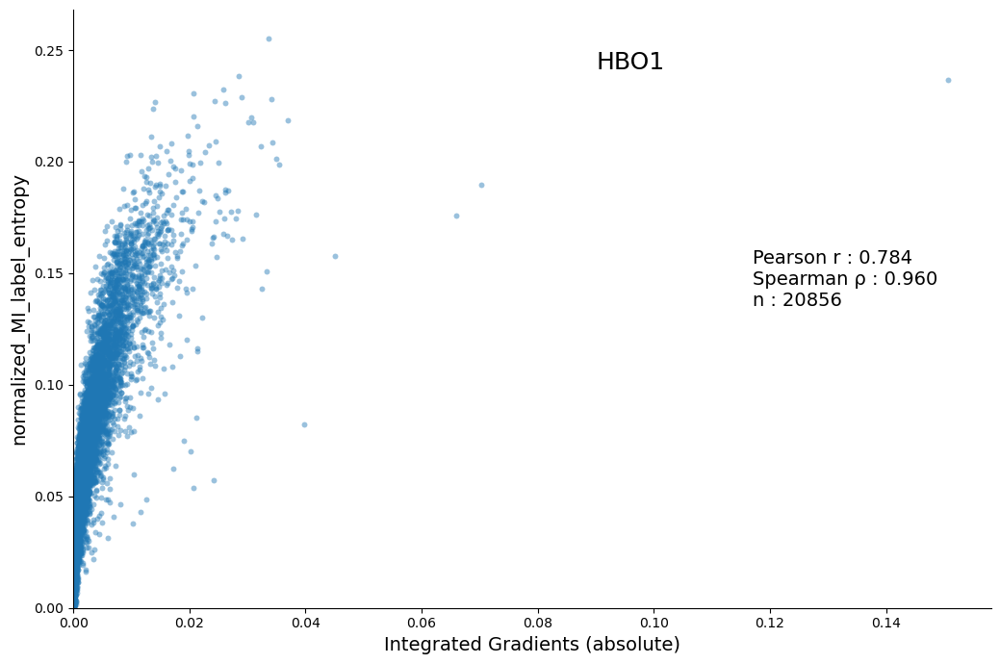

{'spearman_rho': 0.9604384539254005, 'spearman_p': 0.0, 'pearson_r': 0.7843120769267745, 'pearson_p': 0.0, 'n': 20856}


In [11]:
plot_df, corr, out = plot_ig_vs_mi_all_genes(
    mi_df=normalized_MI_treutlein,
    ig_df=integrated_gradients_treutlein,
    dataset_label="HBO1",
)

print(corr)

[saved] /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/MHSPC_IG_vs_MI_all_genes.pdf


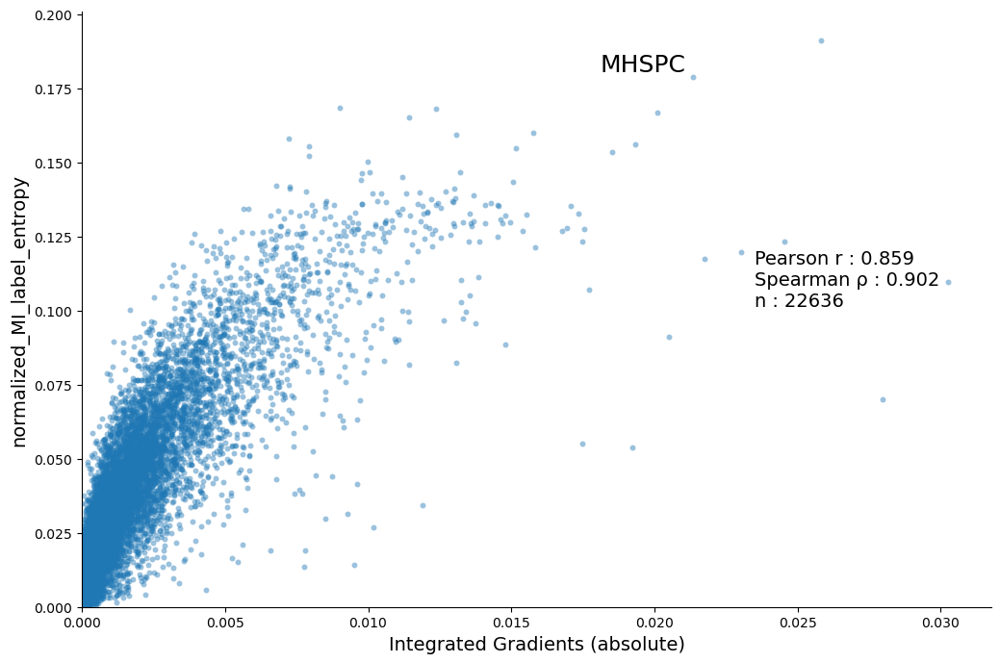

{'spearman_rho': 0.9015634274078219, 'spearman_p': 0.0, 'pearson_r': 0.8587321007151698, 'pearson_p': 0.0, 'n': 22636}


In [12]:
plot_df, corr, out = plot_ig_vs_mi_all_genes(
    mi_df=normalized_MI_weinreb,
    ig_df=integrated_gradients_weinreb,
    dataset_label="MHSPC",
)

print(corr)

# plotting correlation of MI between datasets

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
import pickle
import scanpy as sc
import seaborn as sns
import csv
import os 

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
import pandas as pd
from pathlib import Path

BASE = Path("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel")

def load_mi_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)

    # If a previous run saved the index into a column, drop it
    unnamed = [c for c in df.columns if c.startswith("Unnamed:")]
    if unnamed:
        df = df.drop(columns=unnamed)

    # Guarantee a single, unique index (0..n-1)
    df = df.reset_index(drop=True)

    # Safety check (optional but useful)
    assert df.index.is_unique, f"Index is not unique for {path.name}"

    return df

normalized_MI_junker          = load_mi_csv(BASE / "MI_label_entropy_junker_50_permutations.csv")
normalized_MI_knoblich_day16_1 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day16_1_50_permutations.csv")
normalized_MI_knoblich_day16_2 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day16_2_50_permutations.csv")
normalized_MI_knoblich_day42_1 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day42_1_50_permutations.csv")
normalized_MI_knoblich_day42_2 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day42_2_50_permutations.csv")
normalized_MI_treutlein        = load_mi_csv(BASE / "MI_label_entropy_treutlein_50_permutations.csv")
normalized_MI_weinreb          = load_mi_csv(BASE / "MI_label_entropy_weinreb_50_permutations.csv")
normalized_MI_you1             = load_mi_csv(BASE / "MI_label_entropy_you1_50_permutations.csv")
normalized_MI_you2             = load_mi_csv(BASE / "MI_label_entropy_you2_50_permutations.csv")
normalized_MI_you3             = load_mi_csv(BASE / "MI_label_entropy_you3_50_permutations.csv")
normalized_MI_you4             = load_mi_csv(BASE / "MI_label_entropy_you4_50_permutations.csv")


In [3]:
def prep_for_concat(df, measure, new_col, dataset_name=None):
    """
    Prepare an MI dataframe for safe column-wise concatenation:
      - keeps only (gene, measure)
      - drops NA genes
      - collapses to ONE value per gene (max MI)
      - enforces unique gene index
    """

    # Basic column sanity
    required = {"gene", measure}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(
            f"[{dataset_name}] Missing required columns: {missing}"
        )

    # Reduce to gene-level MI
    out = (
        df[["gene", measure]]
        .dropna(subset=["gene"])
        .groupby("gene", as_index=True)[measure]
        .max()   # biologically sensible for MI ranking
        .to_frame(name=new_col)
    )

    # Hard sanity checks (fail fast)
    if not out.index.is_unique:
        raise RuntimeError(
            f"[{dataset_name}] Gene index is NOT unique after aggregation "
            f"(this should never happen)."
        )

    if out.index.hasnans:
        raise RuntimeError(
            f"[{dataset_name}] Gene index contains NaNs after aggregation."
        )

    return out


In [4]:
# rename mouse and fish gene names to human orthologs

def read_csv_as_dict(file_path, key_column='Mouse Gene', value_column='Human Gene'):
    result_dict = {}
    
    with open(file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        
        for row in csv_reader:
            result_dict[row[key_column]] = row[value_column]
    
    return result_dict

fish_to_human_dic = read_csv_as_dict('/fast/AG_Metzger/philipp/python_files/gene_signature/fish_to_human_dic.csv')
mouse_to_human_dic = read_csv_as_dict("/fast/AG_Metzger/philipp/python_files/gene_signature/human_to_mouse_dic_all_genes.csv")



In [5]:
# convert the gene names to human orthologs
normalized_MI_junker_human = normalized_MI_junker
normalized_MI_weinreb_human = normalized_MI_weinreb
normalized_MI_junker_human["gene"] = normalized_MI_junker["gene"].map(fish_to_human_dic)
normalized_MI_weinreb_human["gene"] = normalized_MI_weinreb["gene"].map(mouse_to_human_dic)


In [6]:
# drop rows with dublicate index
normalized_MI_junker_human = normalized_MI_junker_human[~normalized_MI_junker_human["gene"].duplicated(keep='first')]
normalized_MI_weinreb_human = normalized_MI_weinreb_human[~normalized_MI_weinreb_human["gene"].duplicated(keep='first')]

Single-page PDF saved at /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/correlation_MI_all_plots_in_one.pdf
Single-page PDF saved at /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/correlation_MI_all_plots_in_one.pdf


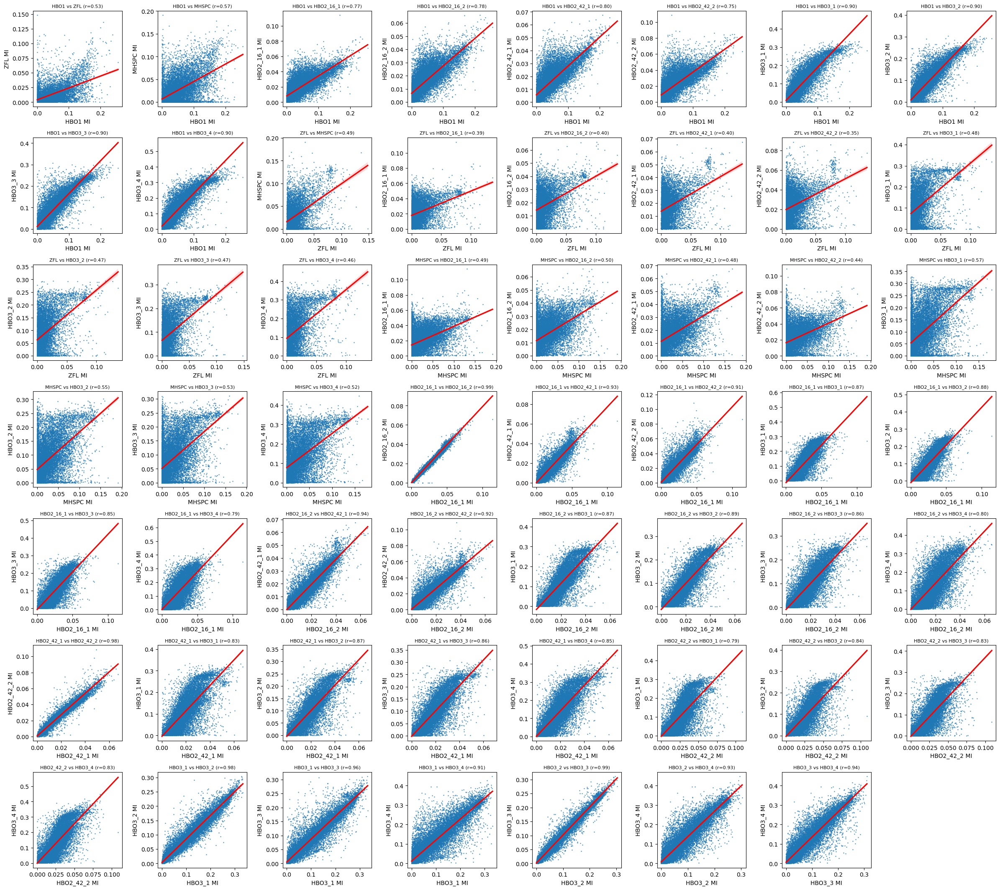

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import math

def plot_all_MI_datasets(datasets, pdf_output_path, measure):
    num_datasets = len(datasets)
    num_plots = (num_datasets * (num_datasets - 1)) // 2
    grid_size = math.ceil(math.sqrt(num_plots))

    fig, axes = plt.subplots(grid_size, grid_size, figsize=(grid_size * 3, grid_size * 3))
    axes = axes.flatten()

    plot_idx = 0

    for i, (dataset1, label1) in enumerate(datasets):
        for j, (dataset2, label2) in enumerate(datasets):
            if i < j:
                ax = axes[plot_idx]
                mi_col1 = f"{label1} MI"
                mi_col2 = f"{label2} MI"
                
                df1 = prep_for_concat(
                    dataset1,
                    measure=measure,
                    new_col=mi_col1,
                    dataset_name=dataset1,
                )

                df2 = prep_for_concat(
                    dataset2,
                    measure=measure,
                    new_col=mi_col2,
                    dataset_name=dataset2,
                )

                # Final concat (now guaranteed safe)
                plot_df = pd.concat([df1, df2], axis=1, join="inner").fillna(0)

                
                

                # Remove genes where MI is exactly zero in either dataset
                #plot_df = plot_df[(plot_df[mi_col1] > 0) & (plot_df[mi_col2] > 0)]

                if not plot_df.empty:
                    x = plot_df[f"{label1} MI"]
                    y = plot_df[f"{label2} MI"]

                    # Scatterplot with regression
                    sns.regplot(x=x, y=y, ax=ax, scatter_kws={"alpha": 0.7, "s": 0.7}, line_kws={"color": "red"})

                    # Compute correlation
                    correlation = x.corr(y)
                    ax.set_title(f"{label1} vs {label2} (r={correlation:.2f})", fontsize=8)
                else:
                    ax.set_title(f"{label1} vs {label2} (No Data)", fontsize=8)

                plot_idx += 1

    # Remove any unused subplots
    for k in range(plot_idx, len(axes)):
        fig.delaxes(axes[k])

    plt.tight_layout()

    with PdfPages(pdf_output_path) as pdf_pages:
        pdf_pages.savefig(fig)

    print(f"Single-page PDF saved at {pdf_output_path}")

    print(f"Single-page PDF saved at {pdf_output_path}")

# List of datasets and their labels
datasets = [
    (normalized_MI_treutlein, "HBO1"),
    (normalized_MI_junker_human, "ZFL"),
    (normalized_MI_weinreb_human, "MHSPC"),
    (normalized_MI_knoblich_day16_1, "HBO2_16_1"),
    (normalized_MI_knoblich_day16_2, "HBO2_16_2"),
    (normalized_MI_knoblich_day42_1, "HBO2_42_1"),
    (normalized_MI_knoblich_day42_2, "HBO2_42_2"),
    (normalized_MI_you1, "HBO3_1"),
    (normalized_MI_you2, "HBO3_2"),
    (normalized_MI_you3, "HBO3_3"),
    (normalized_MI_you4, "HBO3_4")
]

# Output PDF path
pdf_output_path = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/correlation_MI_all_plots_in_one.pdf"


measure = "normalized_MI_label_entropy"


# Generate plot
plot_all_MI_datasets(datasets, pdf_output_path, measure)






# Making plot with MI for all genes sorted along chromosomes 

In [7]:
# ============================================================
# Flexible MI-over-chromosomes plotting (human + mouse + fish)
# - Uses new MI files: column "true_mi"
# - Builds genome ordering per dataset (via genome_info tables)
# - Scatter + Boxplot functions
# - Loop supports per-dataset annotation thresholds
# ============================================================

from typing import Optional, Dict, Callable
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ---------------------------
# 1) Generic flexible helper
# ---------------------------

def add_chromosome_order_flexible(
    df: pd.DataFrame,
    genome_info: pd.DataFrame,
    *,
    gene_col: str = "gene",
    mi_col_in: str = "true_mi",
    mi_col_out: str = "Mutual Information",
    genome_chrom_col: str = '#"chrom"',
    genome_start_col: str = "chromStart",
    chrom_col_out: str = "chrom",
    chromstart_col_out: str = "chromstart",
    genomic_order_col_out: str = "genomic_ordered",
    color_col_out: str = "color",
    chrom_map: Optional[Dict[str, int]] = None,
    chrom_rename: Optional[Dict[str, str]] = None,
    drop_missing_chrom: bool = True,
) -> pd.DataFrame:

    if gene_col not in df.columns:
        raise ValueError(f"df missing gene column '{gene_col}'. Columns: {list(df.columns)}")
    if mi_col_in not in df.columns:
        raise ValueError(f"df missing MI column '{mi_col_in}'. Columns: {list(df.columns)}")
    if genome_chrom_col not in genome_info.columns:
        raise ValueError(f"genome_info missing '{genome_chrom_col}'. Columns: {list(genome_info.columns)}")
    if genome_start_col not in genome_info.columns:
        raise ValueError(f"genome_info missing '{genome_start_col}'. Columns: {list(genome_info.columns)}")

    out = df.copy()

    # standardize MI column name for plotting
    out = out.rename(columns={mi_col_in: mi_col_out})
    out[mi_col_out] = out[mi_col_out].fillna(0)

    # map genome annotations
    out[chrom_col_out] = out[gene_col].map(genome_info[genome_chrom_col])
    out[chromstart_col_out] = out[gene_col].map(genome_info[genome_start_col])

    if drop_missing_chrom:
        out = out.dropna(subset=[chrom_col_out]).copy()

    if chrom_rename:
        out[chrom_col_out] = out[chrom_col_out].replace(chrom_rename)

    # default conversion: chr1.. -> 1, else keep token
    def _default_chrom_to_int(chrom_val):
        if pd.isna(chrom_val):
            return None
        s = str(chrom_val)
        if s.startswith("chr"):
            tail = s[3:]
            if tail.isdigit():
                return int(tail)
            return s
        if s.isdigit():
            return int(s)
        return s

    out["chrom_int"] = out[chrom_col_out].map(_default_chrom_to_int)

    if chrom_map:
        out["chrom_int"] = out["chrom_int"].replace(chrom_map)

    out = out.sort_values(["chrom_int", chromstart_col_out]).copy()
    out[genomic_order_col_out] = range(len(out))

    # ✅ SAFE color computation (works even if chrom_int contains strings)
    chrom_int_num = pd.to_numeric(out["chrom_int"], errors="coerce")  # strings -> NaN
    out[color_col_out] = (chrom_int_num.fillna(0).astype(int) % 2)

    return out


# ---------------------------
# 2) Fish GTF genome table
# ---------------------------

def parse_attributes(attributes_str: str) -> dict:
    attributes = {}
    for attribute in attributes_str.strip().split(";"):
        attribute = attribute.strip()
        if not attribute:
            continue
        key_value = attribute.split(" ", 1)
        if len(key_value) == 2:
            key, value = key_value
            attributes[key] = value.strip('"')
    return attributes


def load_genome_info_fish_from_gtf(gtf_file_path: str) -> pd.DataFrame:
    """
    Extracts (chromosome, start_position, gene_name) from a GTF where feature == 'gene'.
    Returns a DF indexed by gene_name with columns: 'chromosome', 'start_position'.
    """
    gene_info = []
    with open(gtf_file_path, "r") as f:
        for line in f:
            if line.startswith("#"):
                continue
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 9:
                continue
            if fields[2] != "gene":
                continue
            chromosome = fields[0]
            start_position = fields[3]
            attrs = parse_attributes(fields[8])
            gene_name = attrs.get("gene_name", None)
            if gene_name:
                gene_info.append(
                    {"gene_name": gene_name, "chromosome": chromosome, "start_position": start_position}
                )

    genome_info_fish = pd.DataFrame(gene_info)
    genome_info_fish = genome_info_fish.drop_duplicates(subset=["gene_name"])
    genome_info_fish = genome_info_fish.set_index("gene_name")
    return genome_info_fish


def add_chromosome_order_fish_gtf(
    df: pd.DataFrame,
    genome_info_fish: pd.DataFrame,
    *,
    gene_col: str = "gene",
    mi_col_in: str = "true_mi",
    fish_special_map: Optional[Dict[str, int]] = None,
) -> pd.DataFrame:

    if fish_special_map is None:
        fish_special_map = {"MT": 26, "MYCN": 26, "LMO1": 28, "BIRC5": 29}

    df2 = add_chromosome_order_flexible(
        df=df,
        genome_info=genome_info_fish,
        gene_col=gene_col,
        mi_col_in=mi_col_in,
        genome_chrom_col="chromosome",
        genome_start_col="start_position",
        chrom_map=None,
        chrom_rename=None,
    )

    # Make sure chromstart is numeric for correct sorting
    df2["chromstart"] = pd.to_numeric(df2["chromstart"], errors="coerce")

    # Convert chrom to int if possible, else keep token
    def _fish_chrom_to_int(val):
        s = str(val)
        if s.isdigit():
            return int(s)
        return s

    df2["chrom_int"] = df2["chrom"].map(_fish_chrom_to_int)
    df2["chrom_int"] = df2["chrom_int"].replace(fish_special_map)

    # Add chr prefix for display (like before)
    df2["chrom"] = df2["chrom"].map(lambda x: "chr" + str(x))

    # Re-sort and rebuild order + color
    df2 = df2.sort_values(["chrom_int", "chromstart"]).copy()
    df2["genomic_ordered"] = range(len(df2))

    chrom_int_num = pd.to_numeric(df2["chrom_int"], errors="coerce")
    df2["color"] = (chrom_int_num.fillna(0).astype(int) % 2)

    return df2


# ---------------------------
# 3) Plotting from preordered DF
# ---------------------------

def plot_MI_over_chromosomes_preordered(
    df2: pd.DataFrame,
    annotthresh: float,
    filename: str,
    color_palette: str = "blue",
    annotate_label_col: Optional[str] = None,
    out_dir: str = (
        "/fast/AG_Metzger/philipp/python_files/gene_signature/"
        "mutual_information_approach/November_25_ReDo/figures/"
    ),
):
    palettes = {
        "blue": ["#ADD8E6", "darkblue"],
        "green": ["#90EE90", "darkgreen"],
        "orange": ["#FFA07A", "#8B4000"],
    }

    plt.figure(figsize=(15, 5))
    ax = sns.scatterplot(
        data=df2,
        x="genomic_ordered",
        y="Mutual Information",
        hue="color",
        size=0.5,
        alpha=0.5,
        palette=palettes[color_palette],
        legend=False,
    )
    sns.despine()

    labels = (
        df2[annotate_label_col].astype(str).tolist()
        if annotate_label_col is not None
        else df2.index.astype(str).tolist()
    )

    for i in range(len(df2)):
        if df2["Mutual Information"].iloc[i] > annotthresh:
            ax.annotate(
                labels[i],
                (df2["genomic_ordered"].iloc[i], df2["Mutual Information"].iloc[i]),
                fontsize=7,
            )

    plt.gca().set_ylim(bottom=0)
    plt.gca().set_xlim(left=0)

    chromosome_ticks = df2.groupby("chrom")["genomic_ordered"].median()
    tick_labels = [c[3:] if str(c).lower().startswith("chr") else str(c) for c in chromosome_ticks.index]

    plt.xticks(chromosome_ticks.values, tick_labels, rotation=90)
    plt.xlabel("Chromosome")
    plt.ylabel("Mutual Information (bits)", fontsize=9)
    plt.yticks(fontsize=8)

    out_path = Path(out_dir) / filename
    plt.savefig(out_path, format="pdf", bbox_inches="tight")
    plt.show()


def plot_MI_over_chromosomes_mean_preordered(
    df2: pd.DataFrame,
    filename: str,
    color_palette: str = "blue",
    out_dir: str = (
        "/fast/AG_Metzger/philipp/python_files/gene_signature/"
        "mutual_information_approach/November_25_ReDo/figures/"
    ),
):
    palettes = {
        "blue": ["darkblue", "#ADD8E6"],
        "green": ["darkgreen", "#90EE90"],
        "orange": ["#8B4000", "#FFA07A"],
    }

    plt.figure(figsize=(15, 5))

    chrom_order = (
        df2[["chrom", "chrom_int"]]
        .drop_duplicates()
        .sort_values("chrom_int")["chrom"]
        .tolist()
    )

    sns.boxplot(
        data=df2,
        x="chrom",
        y="Mutual Information",
        order=chrom_order,
        palette=palettes[color_palette],
        showfliers=False,
    )
    sns.despine()

    plt.gca().set_ylim(bottom=0)

    labels = [c[3:] if str(c).lower().startswith("chr") else str(c) for c in chrom_order]
    plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)

    plt.xlabel("Chromosome")
    plt.ylabel("Mutual Information (bits)", fontsize=9)
    plt.yticks(fontsize=8)

    out_path = Path(out_dir) / filename
    plt.savefig(out_path, format="pdf", bbox_inches="tight")
    plt.show()


# ---------------------------
# 4) Dataset -> preordering
# ---------------------------

def prepare_preordered_df(
    mi_df: pd.DataFrame,
    prep_fn: Callable[[pd.DataFrame], pd.DataFrame],
) -> pd.DataFrame:
    """
    Wrapper so the loop can call a single interface.
    prep_fn should return a DF with columns:
      'Mutual Information','chrom','chromstart','chrom_int','genomic_ordered','color'
    """
    return prep_fn(mi_df)


# ---------------------------
# 5) Example configs + loop
# ---------------------------

OUT_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/figures/"
)

# Human mapping
HUMAN_CHROM_MAP = {"chrM": 23, "chrX": 24, "chrY": 25}

# Mouse mapping 
MOUSE_CHROM_MAP = {
    "chrM": 20,
    "chrX": 21,
    "chrY": 22,
    "chr1_GL456221v1_random": 1,
}
MOUSE_CHROM_RENAME = {"chr1_GL456221v1_random": "chr1"}

# Fish special mapping 
FISH_SPECIAL_MAP = {
    "MT": 26,
    "MYCN": 2,
    "BIRC5": 5,
    "LMO1": 7,
}

#numbers are NOT chromosomes but ordering bins.

def run_all_chromosome_plots(
    dataset_registry: dict,
    *,
    annotate_label_col: str = "gene",
    out_dir: str = OUT_DIR,
):
    """
    Runs scatter + box plots for all datasets.
    Threshold + color are read per dataset.
    """

    for ds_name, cfg in dataset_registry.items():
        mi_df = cfg["mi_df"]
        prep_fn = cfg["prep_fn"]
        annot_thresh = cfg.get("annot_thresh", 1.2)
        color = cfg.get("color", "blue")

        print(f"[plot] {ds_name} | thresh={annot_thresh} | color={color}")

        df2 = prep_fn(mi_df)

        plot_MI_over_chromosomes_preordered(
            df2=df2,
            annotthresh=annot_thresh,
            filename=f"{ds_name}_MI_over_chromosomes_scatter.pdf",
            color_palette=color,
            annotate_label_col=annotate_label_col,
            out_dir=out_dir,
        )

        plot_MI_over_chromosomes_mean_preordered(
            df2=df2,
            filename=f"{ds_name}_MI_over_chromosomes_box.pdf",
            color_palette=color,
            out_dir=out_dir,
        )





In [8]:
import pandas as pd

genome_info_human = pd.read_csv("human_genome_gene.csv")
genome_info_human = genome_info_human.drop_duplicates(subset=["name2"])
genome_info_human = genome_info_human.set_index("name2")

genome_info_mouse = pd.read_csv("mouse_genome_gene_mm39_2020.csv")
genome_info_mouse = genome_info_mouse.drop_duplicates(subset=["geneName"])
genome_info_mouse = genome_info_mouse.set_index("geneName")

#  Function to parse the attribute field
def parse_attributes(attributes_str):
    attributes = {}
    for attribute in attributes_str.strip().split(';'):
        if attribute.strip():
            key_value = attribute.strip().split(' ', 1)
            if len(key_value) == 2:
                key, value = key_value
                attributes[key] = value.strip('"')
    return attributes

# Function to extract chromosome, gene_name, and start position from a GTF file
def extract_gene_info(gtf_file):
    gene_info = []
    with open(gtf_file, 'r') as file:
        for line in file:
            if line.startswith('#'):
                continue  # Skip header lines
            fields = line.strip().split('\t')
            if len(fields) < 9:
                continue  # Ensure there are enough fields
            feature_type = fields[2]
            if feature_type == 'gene':
                chromosome = fields[0]
                start_position = fields[3]
                attributes = parse_attributes(fields[8])
                gene_name = attributes.get('gene_name', None)
                if gene_name:
                    gene_info.append({
                        'chromosome': chromosome,
                        'start_position': start_position,
                        'gene_name': gene_name
                    })

    return pd.DataFrame(gene_info)



# Path to the GTF file
gtf_file_path = "zebrafish_genes.gtf"

# Extract gene information and create DataFrame
genome_info_fish = extract_gene_info(gtf_file_path)

# Set gene_name as the index
genome_info_fish.set_index('gene_name', inplace=True)

genome_info_fish = genome_info_fish.loc[~genome_info_fish.index.duplicated(keep='first')]



/tmp/ipykernel_2568586/907646517.py:3: DtypeWarning: Columns (23,36) have mixed types. Specify dtype option on import or set low_memory=False.
  genome_info_human = pd.read_csv("human_genome_gene.csv")


In [9]:
import pandas as pd
from pathlib import Path

BASE = Path("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel")

def load_mi_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)

    # If a previous run saved the index into a column, drop it
    unnamed = [c for c in df.columns if c.startswith("Unnamed:")]
    if unnamed:
        df = df.drop(columns=unnamed)

    # Guarantee a single, unique index (0..n-1)
    df = df.reset_index(drop=True)

    # Safety check (optional but useful)
    assert df.index.is_unique, f"Index is not unique for {path.name}"

    return df

normalized_MI_junker          = load_mi_csv(BASE / "MI_label_entropy_junker_50_permutations.csv")
normalized_MI_knoblich_day16_1 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day16_1_50_permutations.csv")
normalized_MI_knoblich_day16_2 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day16_2_50_permutations.csv")
normalized_MI_knoblich_day42_1 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day42_1_50_permutations.csv")
normalized_MI_knoblich_day42_2 = load_mi_csv(BASE / "MI_label_entropy_knoblich_day42_2_50_permutations.csv")
normalized_MI_treutlein        = load_mi_csv(BASE / "MI_label_entropy_treutlein_50_permutations.csv")
normalized_MI_weinreb          = load_mi_csv(BASE / "MI_label_entropy_weinreb_50_permutations.csv")
normalized_MI_you1             = load_mi_csv(BASE / "MI_label_entropy_you1_50_permutations.csv")
normalized_MI_you2             = load_mi_csv(BASE / "MI_label_entropy_you2_50_permutations.csv")
normalized_MI_you3             = load_mi_csv(BASE / "MI_label_entropy_you3_50_permutations.csv")
normalized_MI_you4             = load_mi_csv(BASE / "MI_label_entropy_you4_50_permutations.csv")


In [13]:
# ============================================================
# Dataset registry with per-dataset annotation threshold + color
# edit "annot_thresh" and "color" values per dataset
# ============================================================

# ============================================================
# Dataset registry with per-dataset annotation threshold + color
# edit "annot_thresh" and "color" values per dataset
# ============================================================

DATASET_REGISTRY = {
    # ---------------- HUMAN ----------------
    "treutlein": {
        "mi_df": normalized_MI_treutlein,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 2,
        "color": "blue",   # "blue" | "green" | "orange"
    },
    "you1": {
        "mi_df": normalized_MI_you1,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 4.4,
        "color": "blue",
    },
    "you2": {
        "mi_df": normalized_MI_you2,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 4,
        "color": "blue",
    },
    "you3": {
        "mi_df": normalized_MI_you3,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 3.9,
        "color": "blue",
    },
    "you4": {
        "mi_df": normalized_MI_you4,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 4,
        "color": "blue",
    },
    "knoblich_day16_1": {
        "mi_df": normalized_MI_knoblich_day16_1,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 0.35,
        "color": "blue",
    },
    "knoblich_day16_2": {
        "mi_df": normalized_MI_knoblich_day16_2,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 0.3,
        "color": "blue",
    },
    "knoblich_day42_1": {
        "mi_df": normalized_MI_knoblich_day42_1,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 0.175,
        "color": "blue",
    },
    "knoblich_day42_2": {
        "mi_df": normalized_MI_knoblich_day42_2,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_human,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=HUMAN_CHROM_MAP,
        ),
        "annot_thresh": 0.3,
        "color": "blue",
    },

    # ---------------- MOUSE ----------------
    "weinreb": {
        "mi_df": normalized_MI_weinreb,
        "prep_fn": lambda d: add_chromosome_order_flexible(
            d, genome_info_mouse,
            gene_col="gene", mi_col_in="true_mi",
            genome_chrom_col='#"chrom"', genome_start_col="chromStart",
            chrom_map=MOUSE_CHROM_MAP,
            chrom_rename=MOUSE_CHROM_RENAME,
        ),
        "annot_thresh": 1.75,
        "color": "orange",
    },

    # ---------------- FISH ----------------
    "junker": {
        "mi_df": normalized_MI_junker,
        "prep_fn": lambda d: add_chromosome_order_fish_gtf(
            d, genome_info_fish,
            gene_col="gene", mi_col_in="true_mi",
            fish_special_map=FISH_SPECIAL_MAP,
        ),
        "annot_thresh": 0.65,
        "color": "green",
    },
}



# run for all datasets

[plot] treutlein | thresh=2 | color=blue


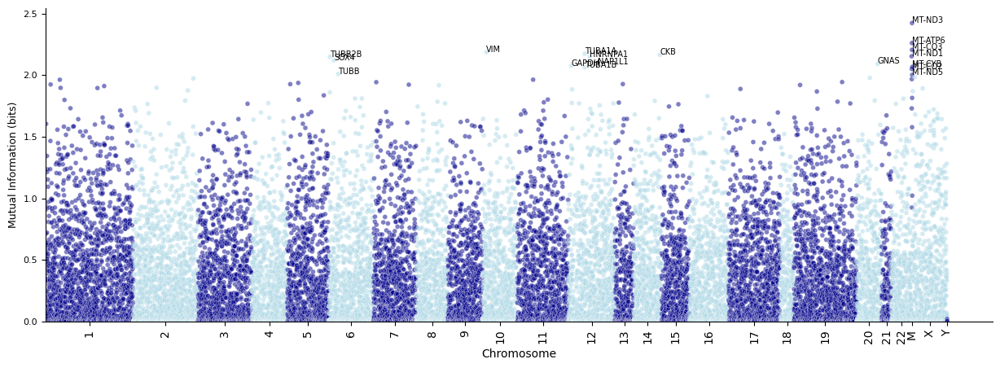

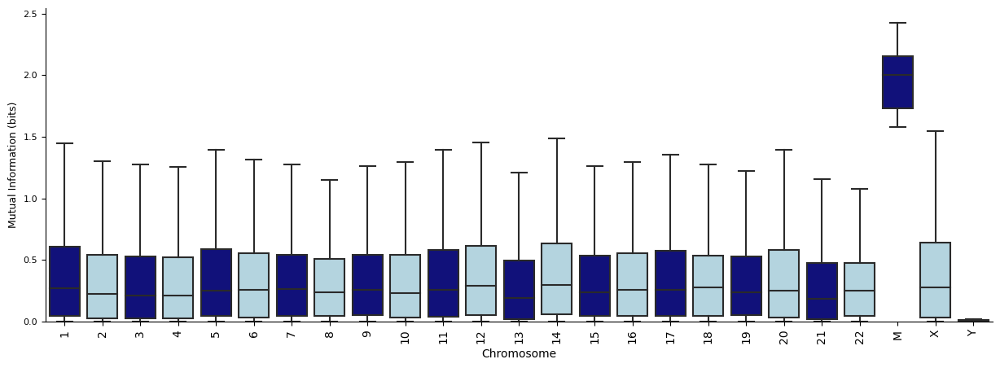

[plot] you1 | thresh=4.4 | color=blue


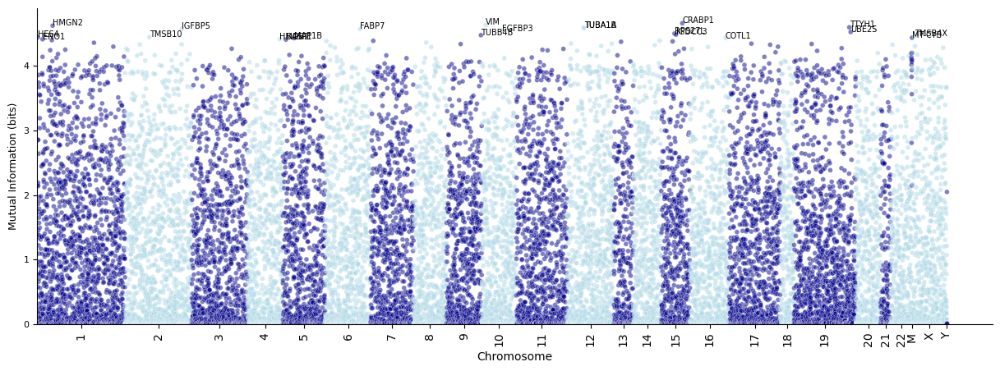

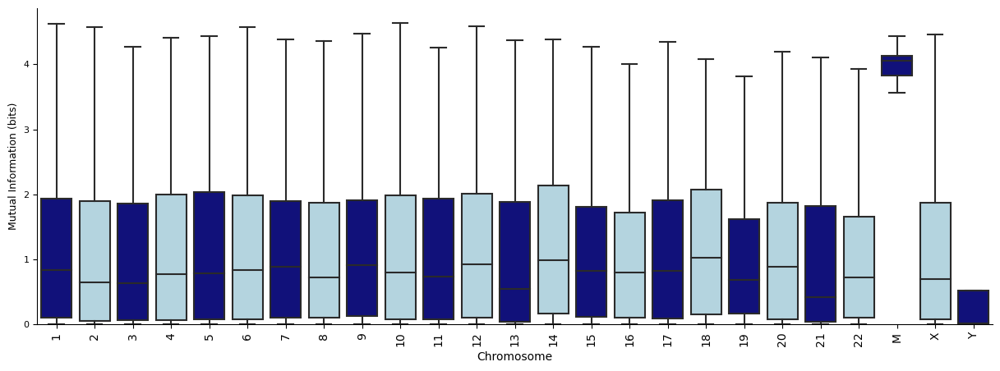

[plot] you2 | thresh=4 | color=blue


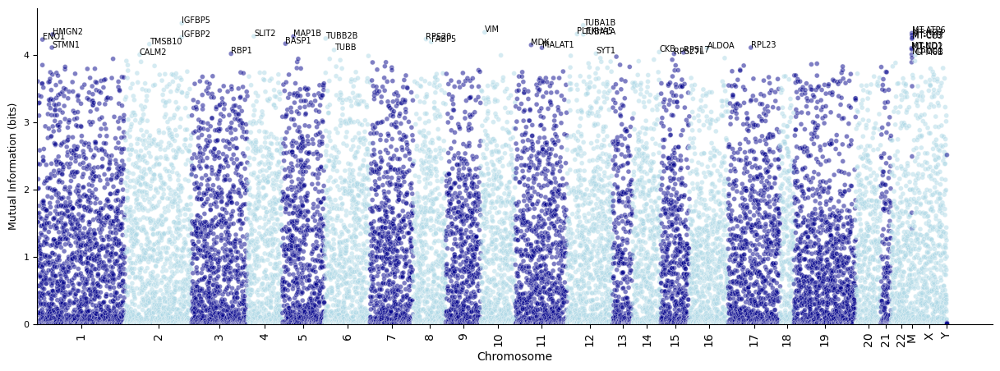

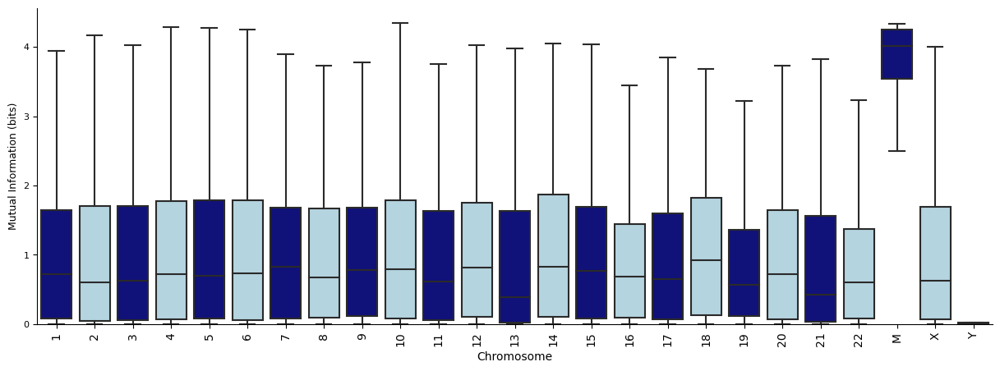

[plot] you3 | thresh=3.9 | color=blue


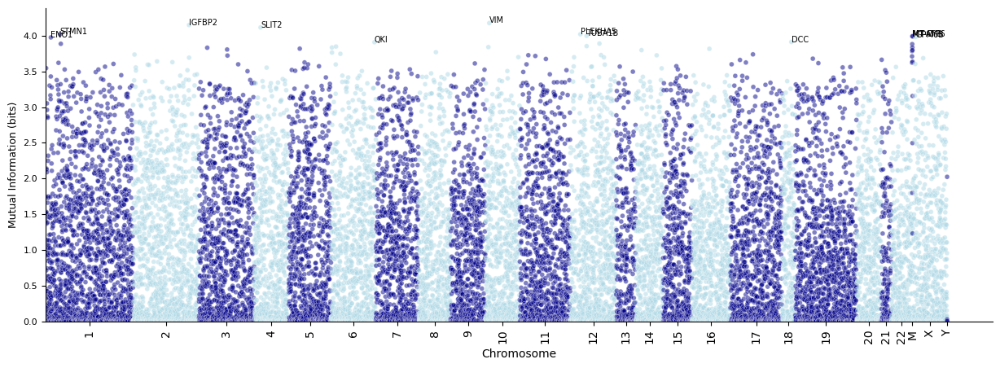

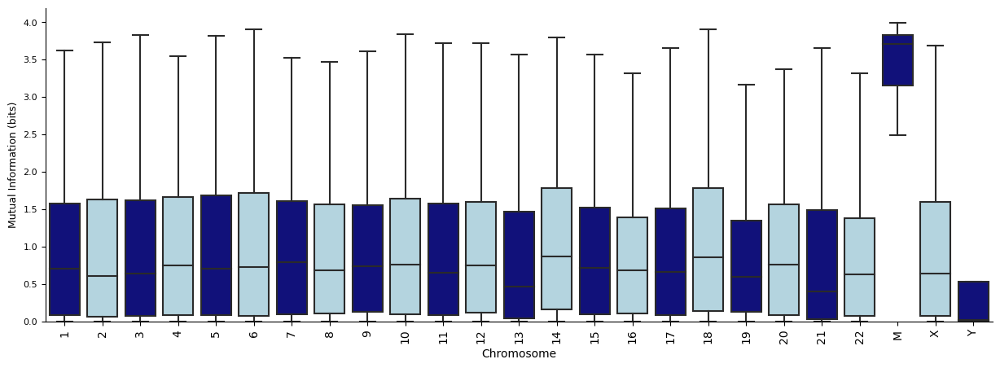

[plot] you4 | thresh=4 | color=blue


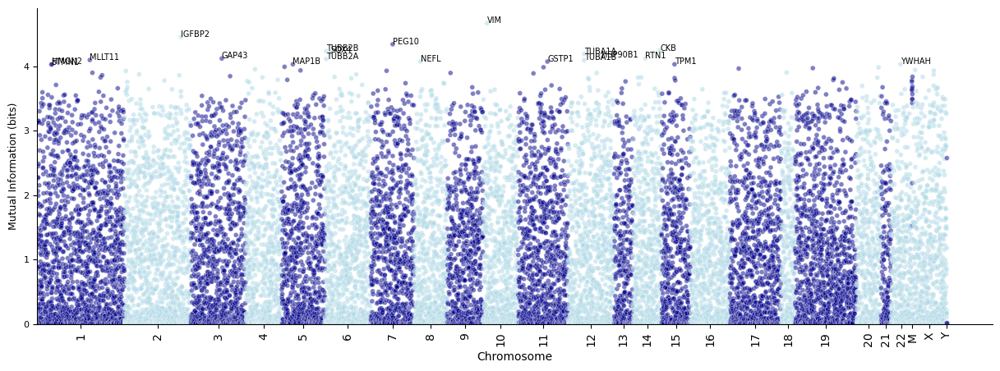

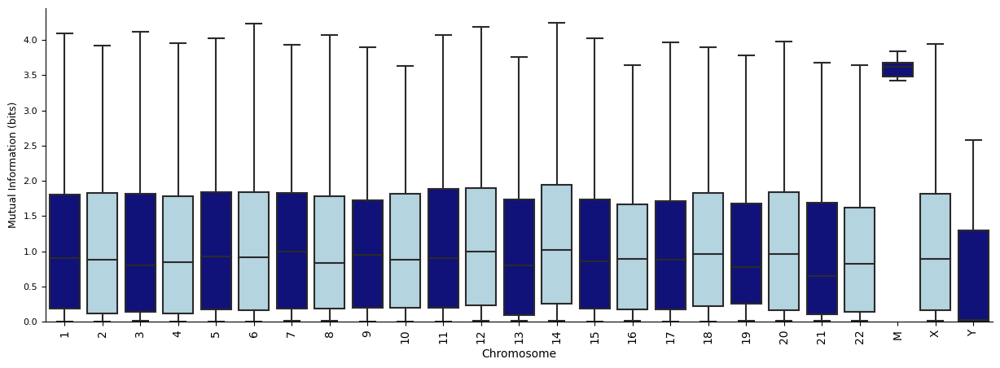

[plot] knoblich_day16_1 | thresh=0.35 | color=blue


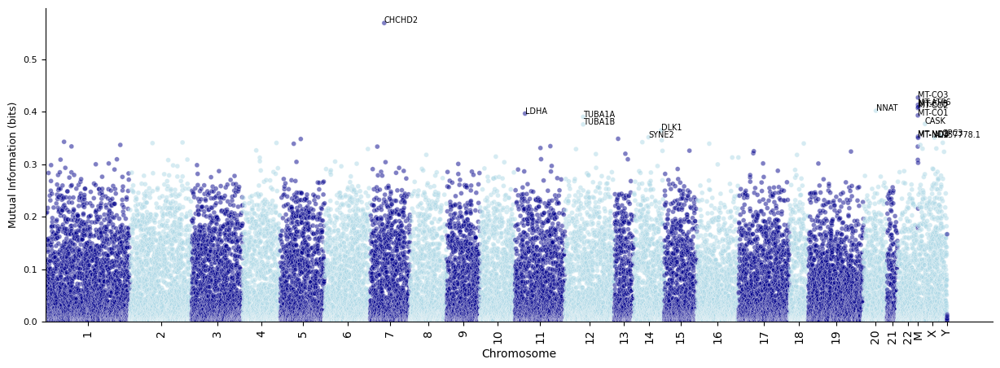

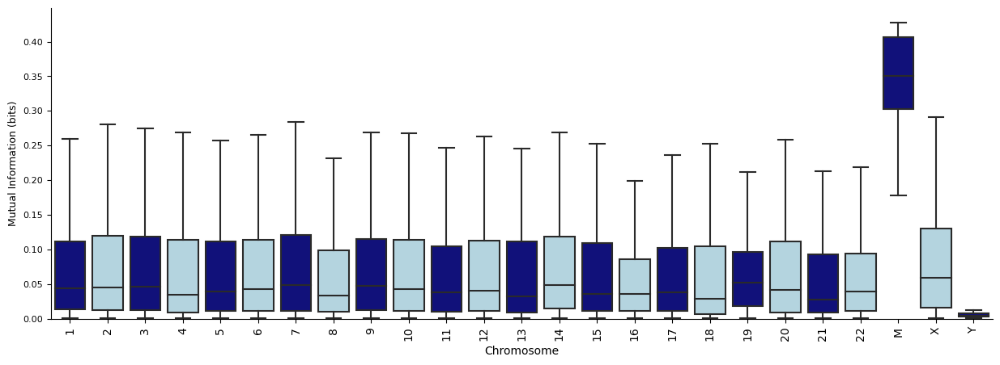

[plot] knoblich_day16_2 | thresh=0.3 | color=blue


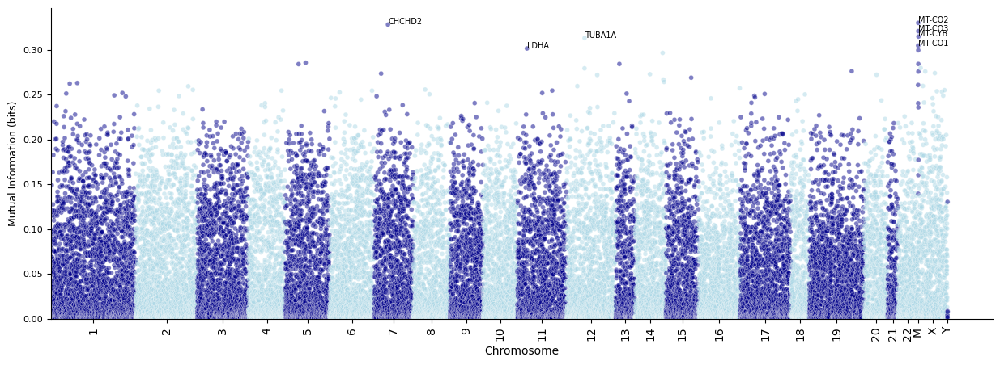

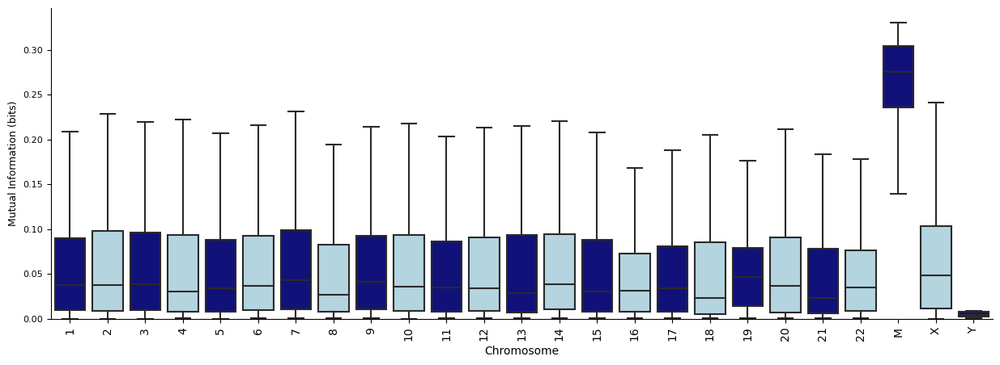

[plot] knoblich_day42_1 | thresh=0.175 | color=blue


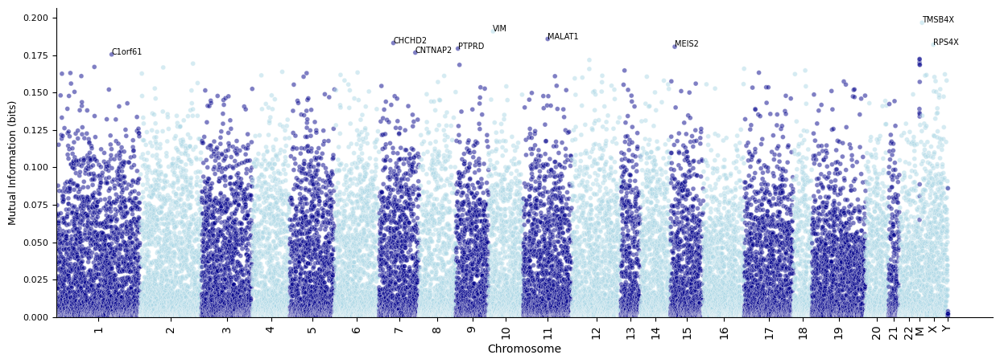

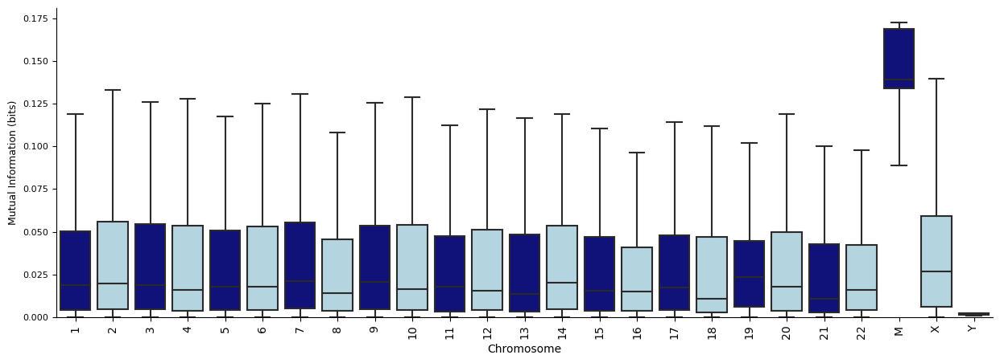

[plot] knoblich_day42_2 | thresh=0.3 | color=blue


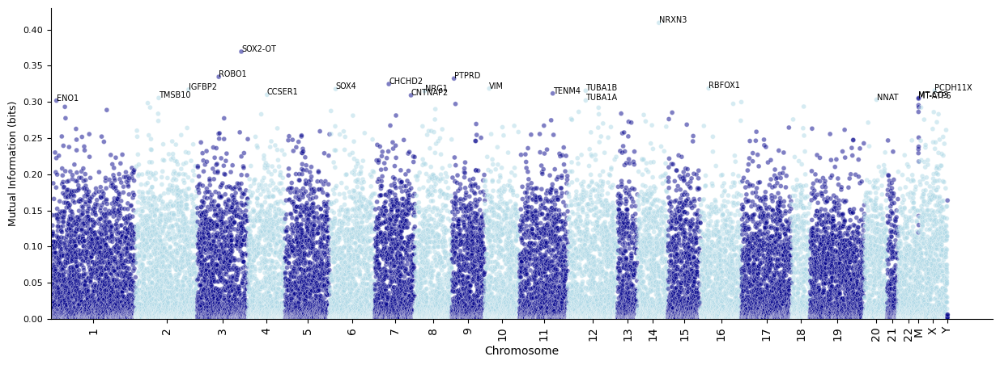

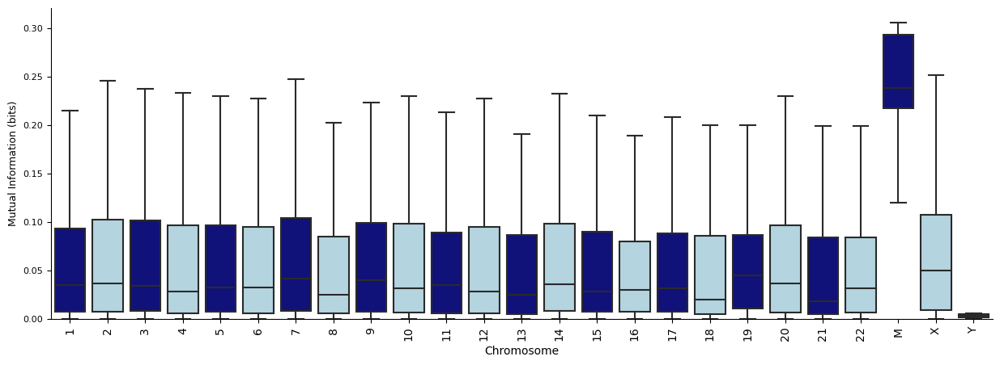

[plot] weinreb | thresh=1.75 | color=orange


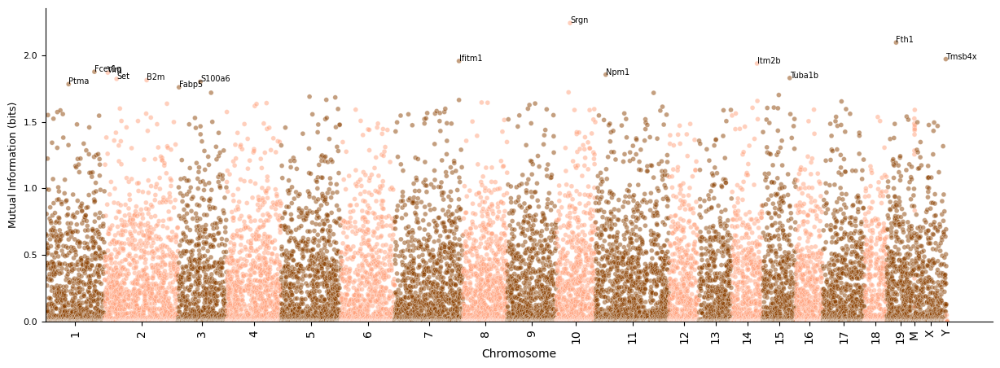

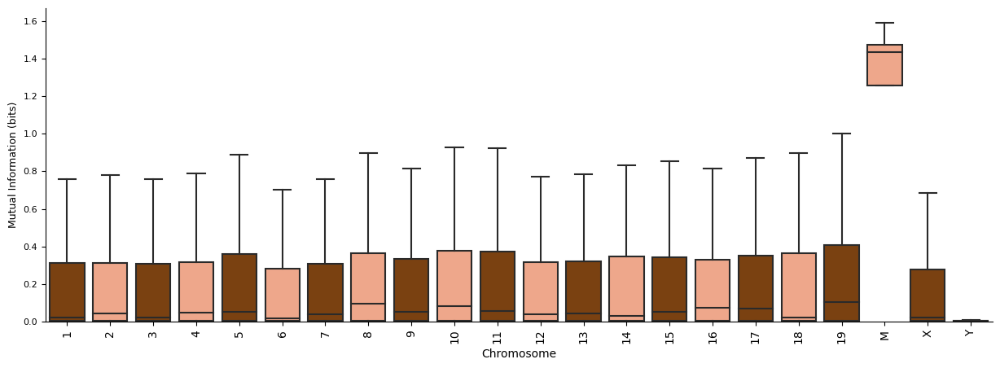

[plot] junker | thresh=0.65 | color=green


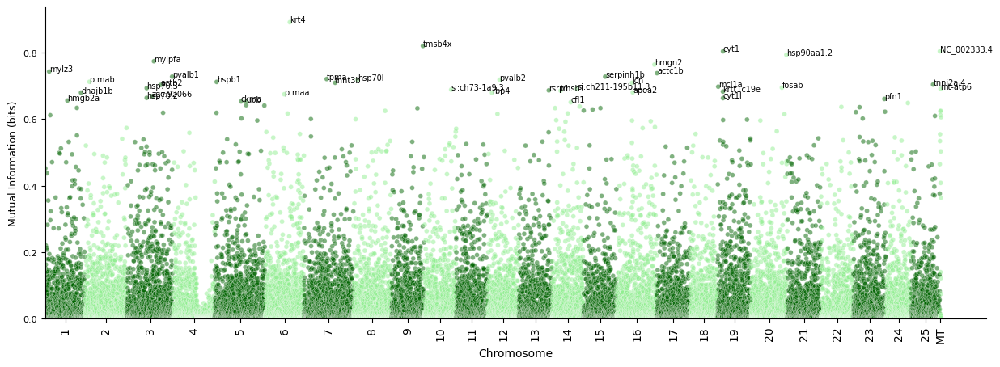

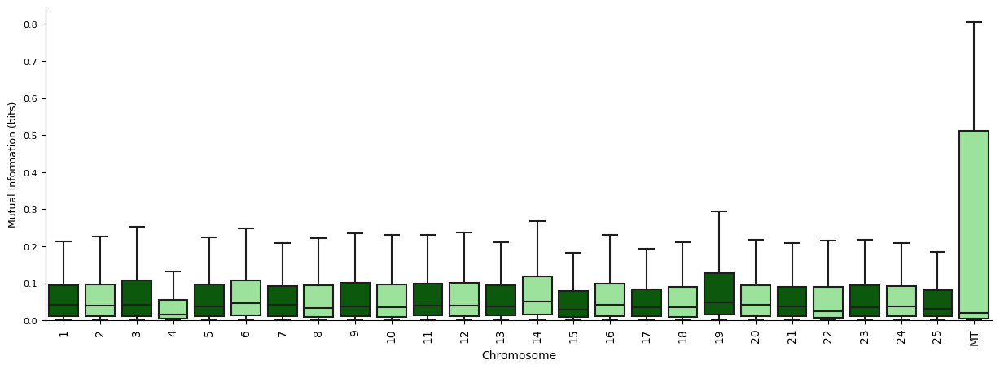

In [14]:
run_all_chromosome_plots(DATASET_REGISTRY, annotate_label_col="gene", out_dir=OUT_DIR)

# gene network plots with normalized Mutual Information 

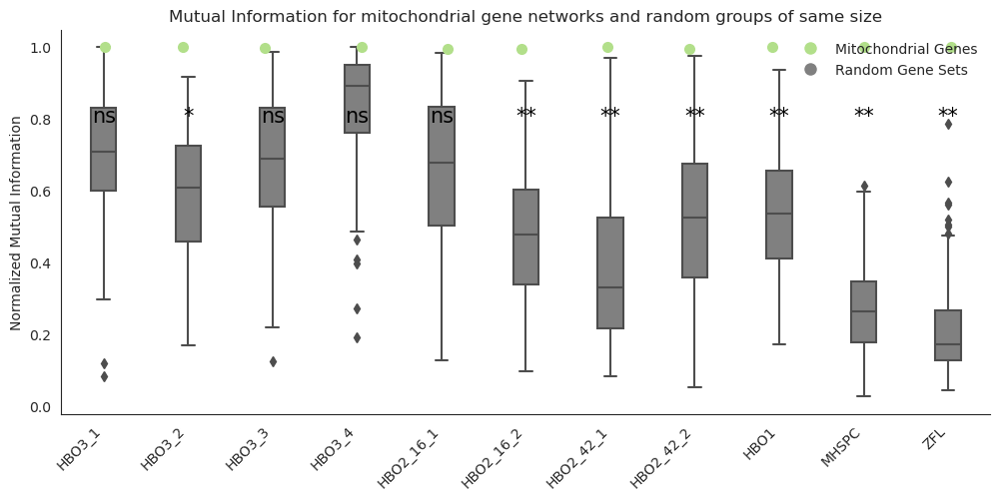

Saved: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/stripplot_normalized_mutual_information_MT_genes_with_stars.pdf


In [27]:
import os
import re
import glob
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# ---------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------
MI_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/gene_network_calcs/"
    "mi_group_mt_and_random_sets_results"
)

DF_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered"
)

OUT_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/figures"
)
os.makedirs(OUT_DIR, exist_ok=True)

OUT_FILE = os.path.join(
    OUT_DIR,
    "stripplot_normalized_mutual_information_MT_genes_with_stars.pdf"
)

FILE_DICT = {
    "treutlein": DF_DIR / "treutlein_all_genes.pkl",
    "weinreb": DF_DIR / "weinreb_all_genes.pkl",
    "junker": DF_DIR / "junker_z5_all_genes.pkl",
    "you1": DF_DIR / "you_stage1_barcode_all_genes.pkl",
    "you2": DF_DIR / "you_stage2_barcode_all_genes.pkl",
    "you3": DF_DIR / "you_stage3_barcode_all_genes.pkl",
    "you4": DF_DIR / "you_stage4_barcode_all_genes.pkl",
    "knoblich_day16_1": DF_DIR / "knoblich_day16_1.pkl",
    "knoblich_day16_2": DF_DIR / "knoblich_day16_2.pkl",
    "knoblich_day42_1": DF_DIR / "knoblich_day42_1.pkl",
    "knoblich_day42_2": DF_DIR / "knoblich_day42_2.pkl",
}

ORDER = [
    "you1", "you2", "you3", "you4",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb", "junker"
]

LABEL_MAP = {
    "treutlein": "HBO1",
    "junker": "ZFL",
    "weinreb": "MHSPC",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}
# ---------------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------------
def calculate_entropy(labels: np.ndarray) -> float:
    labels = np.asarray(labels)
    labels = labels[~pd.isna(labels)]
    if labels.size == 0:
        return np.nan
    uniq, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())

def get_pval_stars(p_val: float) -> str:
    if p_val > 5.00e-02:
        return "ns"
    elif 1.00e-02 < p_val <= 5.00e-02:
        return "*"
    elif 1.00e-03 < p_val <= 1.00e-02:
        return "**"
    elif 1.00e-04 < p_val <= 1.00e-03:
        return "***"
    else:
        return "****"

def empirical_two_tailed_p(random_vals: np.ndarray, x0: float) -> float:
    """
    Two-tailed empirical p-value using the sampled null distribution.
    Uses a +1 correction (recommended) so p is never 0:
        p = (1 + #{|r - mu| >= |x0 - mu|}) / (N + 1)
    """
    r = np.asarray(random_vals, dtype=float)
    mu = float(np.mean(r))
    obs = abs(float(x0) - mu)
    more_extreme = np.sum(np.abs(r - mu) >= obs)
    return float((1.0 + more_extreme) / (r.size + 1.0))

def parse_dataset_key(mi_pkl_path: str) -> str:
    fn = os.path.basename(mi_pkl_path)
    m = re.match(r"MI_mito_random_samples_(.+)_\d+_numba\.pkl$", fn)
    return m.group(1) if m else os.path.splitext(fn)[0]

# ---------------------------------------------------------------------
# LOAD + NORMALIZE + P-VALUES (PER DATASET)
# ---------------------------------------------------------------------
mi_pkls = sorted(glob.glob(os.path.join(MI_DIR, "MI_mito_random_samples_*_numba.pkl")))
if not mi_pkls:
    raise FileNotFoundError(f"No MI pkls found in {MI_DIR}")

rows = []
p_values = {}
debug_scale_checks = []

for mi_pkl in mi_pkls:
    ds = parse_dataset_key(mi_pkl)
    if ds not in FILE_DICT:
        print(f"[skip] dataset '{ds}' not in FILE_DICT")
        continue

    with open(mi_pkl, "rb") as f:
        mi_list = pickle.load(f)

    if not isinstance(mi_list, (list, tuple)) or len(mi_list) < 2:
        raise ValueError(f"Unexpected content in {mi_pkl} (expected list with >=2 entries).")

    mito_raw = float(mi_list[-1])
    random_raw = np.asarray(mi_list[:-1], dtype=float)

    with open(FILE_DICT[ds], "rb") as f:
        df = pickle.load(f)

    if "barcode_cont" not in df.columns:
        raise KeyError(f"{ds}: 'barcode_cont' column not found in {FILE_DICT[ds]}")

    barcodes = np.round(df["barcode_cont"].values, decimals=1)
    H = calculate_entropy(barcodes)
    if H <= 0 or np.isnan(H):
        raise ValueError(f"{ds}: entropy is {H} (cannot normalize).")

    mito = mito_raw / H
    random = random_raw / H

    # empirical p-value (scale-invariant)
    p_raw = empirical_two_tailed_p(random_raw, mito_raw)
    p_norm = empirical_two_tailed_p(random, mito)

    if not np.isclose(p_raw, p_norm, rtol=1e-12, atol=1e-15):
        debug_scale_checks.append((ds, p_raw, p_norm, H))

    p_values[ds] = p_norm

    for v in random:
        rows.append({"Source": ds, "Type": "random", "Mutual Information": float(v)})
    rows.append({"Source": ds, "Type": "mt", "Mutual Information": float(mito)})

plot_df = pd.DataFrame(rows)

present = [d for d in ORDER if d in plot_df["Source"].unique()]
present += [d for d in plot_df["Source"].unique() if d not in present]

plot_df["Source"] = pd.Categorical(plot_df["Source"], categories=present, ordered=True)
x_labels = [LABEL_MAP.get(d, d) for d in present]

if debug_scale_checks:
    print("\n[WARN] Scale-invariance check failed for these datasets:")
    for ds, p_raw, p_norm, H in debug_scale_checks:
        print(f"  - {ds}: p_raw={p_raw:.6g}  p_norm={p_norm:.6g}  H={H:.6g}")
    print("This indicates inconsistent scaling or NaNs/zeros.\n")

# ---------------------------------------------------------------------
# PLOT
# ---------------------------------------------------------------------
sns.set_style("white")
cmap = sns.color_palette("Paired")
color_MT = cmap[2]

plt.figure(figsize=(12, 5))
ax = plt.gca()

df_random = plot_df[plot_df["Type"] == "random"]
df_mt = plot_df[plot_df["Type"] == "mt"]

sns.boxplot(
    data=df_random,
    x="Source",
    y="Mutual Information",
    color="grey",
    width=0.3,
    ax=ax
)
sns.stripplot(
    data=df_mt,
    x="Source",
    y="Mutual Information",
    color=color_MT,
    size=8,
    ax=ax
)
sns.despine()

for i, ds in enumerate(present):
    if ds not in p_values:
        continue
    star = get_pval_stars(p_values[ds])
    ax.text(
        i, 0.75, star,
        ha="center", va="bottom",
        fontsize=15, color="black",
        transform=ax.get_xaxis_transform()
    )

ax.set_xticks(range(len(present)))
ax.set_xticklabels(x_labels, rotation=45, ha="right")

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=color_MT, markersize=10, label="Mitochondrial Genes"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="grey", markersize=10, label="Random Gene Sets"),
]
ax.legend(handles=legend_elements, frameon=False)

ax.set_title("Mutual Information for mitochondrial gene networks and random groups of same size")
ax.set_ylabel("Normalized Mutual Information")
ax.set_xlabel("")

plt.savefig(OUT_FILE, bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_FILE}")


# per cell ID (not in paper)

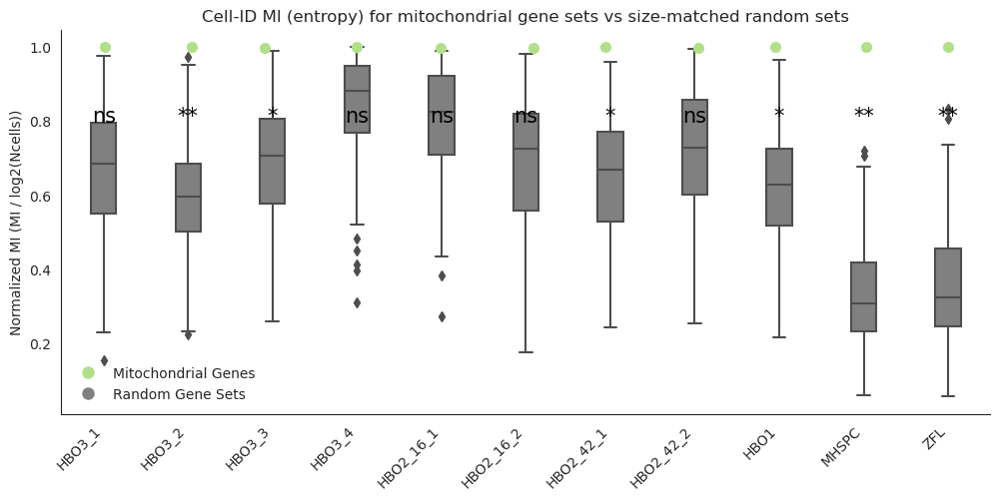

Saved: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/stripplot_normalized_cellid_MI_MT_genes_with_stars.pdf


In [28]:
# plot_cellid_vs_gene_group_MI_stripplot.py
#
# Same plotting logic as your MT-vs-random stripplot,
# but for the NEW cell-id MI files (MI(cell_id ; expr_bin) = entropy of expr_bin).
#
# - Loads pkl outputs from: mi_cellid_vs_gene_groups_results
# - Treats last entry as mito (mt) score, preceding entries as random sets
# - Normalizes by log2(N_cells) (optional but recommended for cross-dataset comparability)
# - Empirical two-tailed p-values vs the sampled null (random sets), with +1 correction
# - Boxplot for random + point for mt + stars

import os
import re
import glob
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# ---------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------
MI_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/gene_network_calcs/"
    "mi_cellid_vs_gene_groups_results"
)

DF_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered"
)

OUT_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/figures"
)
os.makedirs(OUT_DIR, exist_ok=True)

# Toggle normalization:
# - True: divide by log2(N_cells) so values are in [0,1] (max entropy for N cells)
# - False: plot raw MI/entropy in bits
NORMALIZE_BY_LOG2_NCELLS = True

OUT_FILE = os.path.join(
    OUT_DIR,
    "stripplot_cellid_MI_MT_genes_with_stars.pdf"
    if not NORMALIZE_BY_LOG2_NCELLS
    else "stripplot_normalized_cellid_MI_MT_genes_with_stars.pdf"
)

FILE_DICT = {
    "treutlein": DF_DIR / "treutlein_all_genes.pkl",
    "weinreb": DF_DIR / "weinreb_all_genes.pkl",
    "junker": DF_DIR / "junker_z5_all_genes.pkl",
    "you1": DF_DIR / "you_stage1_barcode_all_genes.pkl",
    "you2": DF_DIR / "you_stage2_barcode_all_genes.pkl",
    "you3": DF_DIR / "you_stage3_barcode_all_genes.pkl",
    "you4": DF_DIR / "you_stage4_barcode_all_genes.pkl",
    "knoblich_day16_1": DF_DIR / "knoblich_day16_1.pkl",
    "knoblich_day16_2": DF_DIR / "knoblich_day16_2.pkl",
    "knoblich_day42_1": DF_DIR / "knoblich_day42_1.pkl",
    "knoblich_day42_2": DF_DIR / "knoblich_day42_2.pkl",
}

ORDER = [
    "you1", "you2", "you3", "you4",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb", "junker"
]

LABEL_MAP = {
    "treutlein": "HBO1",
    "junker": "ZFL",
    "weinreb": "MHSPC",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}
# ---------------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------------
def get_pval_stars(p_val: float) -> str:
    if p_val > 5.00e-02:
        return "ns"
    elif 1.00e-02 < p_val <= 5.00e-02:
        return "*"
    elif 1.00e-03 < p_val <= 1.00e-02:
        return "**"
    elif 1.00e-04 < p_val <= 1.00e-03:
        return "***"
    else:
        return "****"

def empirical_two_tailed_p(random_vals: np.ndarray, x0: float) -> float:
    """
    Two-tailed empirical p-value using sampled null distribution.
    Uses +1 correction so p never becomes 0:
        p = (1 + #{|r - mu| >= |x0 - mu|}) / (N + 1)
    """
    r = np.asarray(random_vals, dtype=float)
    mu = float(np.mean(r))
    obs = abs(float(x0) - mu)
    more_extreme = np.sum(np.abs(r - mu) >= obs)
    return float((1.0 + more_extreme) / (r.size + 1.0))

def parse_dataset_key(mi_pkl_path: str) -> str:
    fn = os.path.basename(mi_pkl_path)
    m = re.match(r"MI_cellid_vs_gene_groups_(.+)_\d+_numba\.pkl$", fn)
    return m.group(1) if m else os.path.splitext(fn)[0]

def safe_log2_ncells(df: pd.DataFrame) -> float:
    n = int(df.shape[0])
    if n <= 1:
        return np.nan
    return float(np.log2(n))

# ---------------------------------------------------------------------
# LOAD + (OPTIONAL) NORMALIZE + P-VALUES (PER DATASET)
# ---------------------------------------------------------------------
mi_pkls = sorted(glob.glob(os.path.join(MI_DIR, "MI_cellid_vs_gene_groups_*_numba.pkl")))
if not mi_pkls:
    raise FileNotFoundError(f"No MI pkls found in {MI_DIR}")

rows = []
p_values = {}
debug_scale_checks = []

for mi_pkl in mi_pkls:
    ds = parse_dataset_key(mi_pkl)
    if ds not in FILE_DICT:
        print(f"[skip] dataset '{ds}' not in FILE_DICT")
        continue

    with open(mi_pkl, "rb") as f:
        mi_list = pickle.load(f)

    if not isinstance(mi_list, (list, tuple)) or len(mi_list) < 2:
        raise ValueError(f"Unexpected content in {mi_pkl} (expected list with >=2 entries).")

    mito_raw = float(mi_list[-1])
    random_raw = np.asarray(mi_list[:-1], dtype=float)

    # Load df only to get N_cells for optional normalization
    with open(FILE_DICT[ds], "rb") as f:
        df = pickle.load(f)

    norm_factor = 1.0
    if NORMALIZE_BY_LOG2_NCELLS:
        Hmax = safe_log2_ncells(df)
        if np.isnan(Hmax) or Hmax <= 0:
            raise ValueError(f"{ds}: log2(N_cells) is {Hmax} (cannot normalize).")
        norm_factor = Hmax

    mito = mito_raw / norm_factor
    random = random_raw / norm_factor

    # empirical p-value (scale-invariant if scaling by constant)
    p_raw = empirical_two_tailed_p(random_raw, mito_raw)
    p_norm = empirical_two_tailed_p(random, mito)
    if not np.isclose(p_raw, p_norm, rtol=1e-12, atol=1e-15):
        debug_scale_checks.append((ds, p_raw, p_norm, norm_factor))

    p_values[ds] = p_norm

    for v in random:
        rows.append({"Source": ds, "Type": "random", "Mutual Information": float(v)})
    rows.append({"Source": ds, "Type": "mt", "Mutual Information": float(mito)})

plot_df = pd.DataFrame(rows)

present = [d for d in ORDER if d in plot_df["Source"].unique()]
present += [d for d in plot_df["Source"].unique() if d not in present]

plot_df["Source"] = pd.Categorical(plot_df["Source"], categories=present, ordered=True)
x_labels = [LABEL_MAP.get(d, d) for d in present]

if debug_scale_checks:
    print("\n[WARN] Scale-invariance check failed for these datasets:")
    for ds, p_raw, p_norm, nf in debug_scale_checks:
        print(f"  - {ds}: p_raw={p_raw:.6g}  p_norm={p_norm:.6g}  norm_factor={nf:.6g}")
    print("This indicates inconsistent scaling or NaNs/zeros.\n")

# ---------------------------------------------------------------------
# PLOT
# ---------------------------------------------------------------------
sns.set_style("white")
cmap = sns.color_palette("Paired")
color_MT = cmap[2]

plt.figure(figsize=(12, 5))
ax = plt.gca()

df_random = plot_df[plot_df["Type"] == "random"]
df_mt = plot_df[plot_df["Type"] == "mt"]

sns.boxplot(
    data=df_random,
    x="Source",
    y="Mutual Information",
    color="grey",
    width=0.3,
    ax=ax
)
sns.stripplot(
    data=df_mt,
    x="Source",
    y="Mutual Information",
    color=color_MT,
    size=8,
    ax=ax
)
sns.despine()

for i, ds in enumerate(present):
    if ds not in p_values:
        continue
    star = get_pval_stars(p_values[ds])
    ax.text(
        i, 0.75, star,
        ha="center", va="bottom",
        fontsize=15, color="black",
        transform=ax.get_xaxis_transform()
    )

ax.set_xticks(range(len(present)))
ax.set_xticklabels(x_labels, rotation=45, ha="right")

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=color_MT, markersize=10, label="Mitochondrial Genes"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="grey", markersize=10, label="Random Gene Sets"),
]
ax.legend(handles=legend_elements, frameon=False)

if NORMALIZE_BY_LOG2_NCELLS:
    ax.set_title("Cell-ID MI (entropy) for mitochondrial gene sets vs size-matched random sets")
    ax.set_ylabel("Normalized MI (MI / log2(Ncells))")
else:
    ax.set_title("Cell-ID MI (entropy, bits) for mitochondrial gene sets vs size-matched random sets")
    ax.set_ylabel("MI / Entropy (bits)")

ax.set_xlabel("")

plt.savefig(OUT_FILE, bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_FILE}")


# for stratified gene pool (same entropy as MT genes)

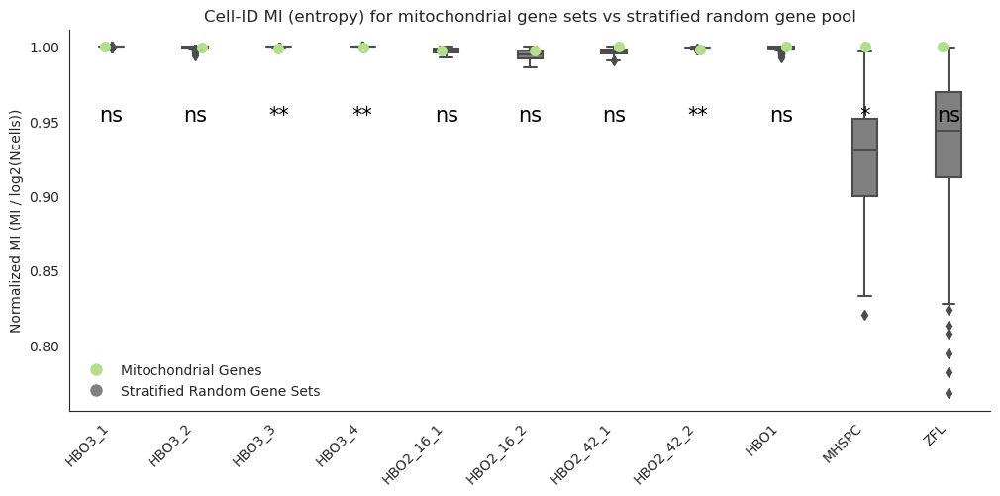

Saved: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/stripplot_normalized_cellid_MI_MT_genes_vs_STRATIFIED_random_with_stars.pdf


In [16]:
#!/usr/bin/env python3
# plot_cellid_MI_MT_vs_stratified_random_stripplot.py
#
# Plot cell-id MI (entropy) for MT gene set vs *stratified random gene pool* controls.
#
# Input files are dict-pkls produced by mi_group_stratified_random.py, e.g.:
#   MI_cellid_stratified_random_knoblich_day16_2_150_round1_S10.pkl
#
# Expected dict keys:
#   - "dataset" (str)
#   - "mt_value" (float)
#   - "random_stratified" (list[float])
#   - (optional) "random_plain" (list[float] or None)
#   - "n_cells" (int) [optional; we also compute from DF for normalization]
#
# - Treats mt_value as MT score and random_stratified as null distribution
# - Optional normalization by log2(N_cells)
# - Empirical two-tailed p-values vs sampled null (with +1 correction)
# - Boxplot for stratified random + point for MT + stars

import os
import re
import glob
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from typing import Any, Dict

# ---------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------
MI_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/gene_network_calcs/"
    "mi_cellid_stratified_random_results"
)

DF_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered"
)

OUT_DIR = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/figures"
)
os.makedirs(OUT_DIR, exist_ok=True)

# Toggle normalization:
# - True: divide by log2(N_cells) so values are in [0,1] (max entropy for N cells)
# - False: plot raw MI/entropy in bits
NORMALIZE_BY_LOG2_NCELLS = True

OUT_FILE = os.path.join(
    OUT_DIR,
    "stripplot_cellid_MI_MT_genes_vs_STRATIFIED_random_with_stars.pdf"
    if not NORMALIZE_BY_LOG2_NCELLS
    else "stripplot_normalized_cellid_MI_MT_genes_vs_STRATIFIED_random_with_stars.pdf"
)

FILE_DICT = {
    "treutlein": DF_DIR / "treutlein_all_genes.pkl",
    "weinreb": DF_DIR / "weinreb_all_genes.pkl",
    "junker": DF_DIR / "junker_z5_all_genes.pkl",
    "you1": DF_DIR / "you_stage1_barcode_all_genes.pkl",
    "you2": DF_DIR / "you_stage2_barcode_all_genes.pkl",
    "you3": DF_DIR / "you_stage3_barcode_all_genes.pkl",
    "you4": DF_DIR / "you_stage4_barcode_all_genes.pkl",
    "knoblich_day16_1": DF_DIR / "knoblich_day16_1.pkl",
    "knoblich_day16_2": DF_DIR / "knoblich_day16_2.pkl",
    "knoblich_day42_1": DF_DIR / "knoblich_day42_1.pkl",
    "knoblich_day42_2": DF_DIR / "knoblich_day42_2.pkl",
}

ORDER = [
    "you1", "you2", "you3", "you4",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb", "junker"
]

LABEL_MAP = {
    "treutlein": "HBO1",
    "junker": "ZFL",
    "weinreb": "MHSPC",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}

# ---------------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------------
def get_pval_stars(p_val: float) -> str:
    if p_val > 5.00e-02:
        return "ns"
    elif 1.00e-02 < p_val <= 5.00e-02:
        return "*"
    elif 1.00e-03 < p_val <= 1.00e-02:
        return "**"
    elif 1.00e-04 < p_val <= 1.00e-03:
        return "***"
    else:
        return "****"

def empirical_two_tailed_p(random_vals: np.ndarray, x0: float) -> float:
    """
    Two-tailed empirical p-value using sampled null distribution.
    Uses +1 correction so p never becomes 0:
        p = (1 + #{|r - mu| >= |x0 - mu|}) / (N + 1)
    """
    r = np.asarray(random_vals, dtype=float)
    if r.size == 0:
        return np.nan
    mu = float(np.mean(r))
    obs = abs(float(x0) - mu)
    more_extreme = np.sum(np.abs(r - mu) >= obs)
    return float((1.0 + more_extreme) / (r.size + 1.0))

def parse_dataset_key(mi_pkl_path: str) -> str:
    """
    Matches your filenames, e.g.:
      MI_cellid_stratified_random_knoblich_day16_2_150_round1_S10.pkl
    -> returns "knoblich_day16_2"
    """
    fn = os.path.basename(mi_pkl_path)
    m = re.match(
        r"MI_cellid_stratified_random_(.+)_\d+_round\d+_S\d+\.pkl$",
        fn
    )
    return m.group(1) if m else os.path.splitext(fn)[0]

def safe_log2_ncells_from_df(df: pd.DataFrame) -> float:
    n = int(df.shape[0])
    if n <= 1:
        return np.nan
    return float(np.log2(n))

def load_stratified_result(path: str) -> Dict[str, Any]:
    with open(path, "rb") as f:
        obj = pickle.load(f)
    if not isinstance(obj, dict):
        raise ValueError(f"{path}: expected dict, got {type(obj)}")
    # minimal required keys
    if "mt_value" not in obj or "random_stratified" not in obj:
        raise ValueError(
            f"{path}: dict missing required keys. "
            f"Need at least 'mt_value' and 'random_stratified'. Keys={list(obj.keys())}"
        )
    return obj

# ---------------------------------------------------------------------
# LOAD + (OPTIONAL) NORMALIZE + P-VALUES (PER DATASET)
# ---------------------------------------------------------------------
mi_pkls = sorted(glob.glob(os.path.join(MI_DIR, "MI_cellid_stratified_random_*_round*_S*.pkl")))
if not mi_pkls:
    raise FileNotFoundError(
        f"No MI pkls found in {MI_DIR}\n"
        f"Expected pattern: MI_cellid_stratified_random_*_round*_S*.pkl"
    )

rows = []
p_values = {}
debug_scale_checks = []

for mi_pkl in mi_pkls:
    ds = parse_dataset_key(mi_pkl)
    if ds not in FILE_DICT:
        print(f"[skip] dataset '{ds}' not in FILE_DICT")
        continue

    res = load_stratified_result(mi_pkl)

    mito_raw = float(res["mt_value"])
    random_raw = np.asarray(res["random_stratified"], dtype=float)

    if random_raw.size < 1:
        raise ValueError(f"{mi_pkl}: 'random_stratified' is empty.")

    # Load df only to get N_cells for optional normalization
    with open(FILE_DICT[ds], "rb") as f:
        df = pickle.load(f)

    norm_factor = 1.0
    if NORMALIZE_BY_LOG2_NCELLS:
        Hmax = safe_log2_ncells_from_df(df)
        if np.isnan(Hmax) or Hmax <= 0:
            raise ValueError(f"{ds}: log2(N_cells) is {Hmax} (cannot normalize).")
        norm_factor = Hmax

    mito = mito_raw / norm_factor
    random = random_raw / norm_factor

    # empirical p-value (scale-invariant if scaling by constant)
    p_raw = empirical_two_tailed_p(random_raw, mito_raw)
    p_norm = empirical_two_tailed_p(random, mito)
    if not np.isclose(p_raw, p_norm, rtol=1e-12, atol=1e-15):
        debug_scale_checks.append((ds, p_raw, p_norm, norm_factor))

    p_values[ds] = p_norm

    for v in random:
        rows.append({"Source": ds, "Type": "random_stratified", "Mutual Information": float(v)})
    rows.append({"Source": ds, "Type": "mt", "Mutual Information": float(mito)})

plot_df = pd.DataFrame(rows)

present = [d for d in ORDER if d in plot_df["Source"].unique()]
present += [d for d in plot_df["Source"].unique() if d not in present]

plot_df["Source"] = pd.Categorical(plot_df["Source"], categories=present, ordered=True)
x_labels = [LABEL_MAP.get(d, d) for d in present]

if debug_scale_checks:
    print("\n[WARN] Scale-invariance check failed for these datasets:")
    for ds, p_raw, p_norm, nf in debug_scale_checks:
        print(f"  - {ds}: p_raw={p_raw:.6g}  p_norm={p_norm:.6g}  norm_factor={nf:.6g}")
    print("This indicates inconsistent scaling or NaNs/zeros.\n")

# ---------------------------------------------------------------------
# PLOT
# ---------------------------------------------------------------------
sns.set_style("white")
cmap = sns.color_palette("Paired")
color_MT = cmap[2]

plt.figure(figsize=(12, 5))
ax = plt.gca()

df_random = plot_df[plot_df["Type"] == "random_stratified"]
df_mt = plot_df[plot_df["Type"] == "mt"]

sns.boxplot(
    data=df_random,
    x="Source",
    y="Mutual Information",
    color="grey",
    width=0.3,
    ax=ax
)
sns.stripplot(
    data=df_mt,
    x="Source",
    y="Mutual Information",
    color=color_MT,
    size=8,
    ax=ax
)
sns.despine()

for i, ds in enumerate(present):
    if ds not in p_values:
        continue
    star = get_pval_stars(p_values[ds])
    ax.text(
        i, 0.75, star,
        ha="center", va="bottom",
        fontsize=15, color="black",
        transform=ax.get_xaxis_transform()
    )

ax.set_xticks(range(len(present)))
ax.set_xticklabels(x_labels, rotation=45, ha="right")

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=color_MT, markersize=10, label="Mitochondrial Genes"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="grey", markersize=10, label="Stratified Random Gene Sets"),
]
ax.legend(handles=legend_elements, frameon=False)

if NORMALIZE_BY_LOG2_NCELLS:
    ax.set_title("Cell-ID MI (entropy) for mitochondrial gene sets vs stratified random gene pool")
    ax.set_ylabel("Normalized MI (MI / log2(Ncells))")
else:
    ax.set_title("Cell-ID MI (entropy, bits) for mitochondrial gene sets vs stratified random gene pool")
    ax.set_ylabel("MI / Entropy (bits)")

ax.set_xlabel("")

plt.savefig(OUT_FILE, bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_FILE}")


In [29]:
#!/usr/bin/env python3
# sanity_check_cellid_entropy_collisions.py
#
# For each dataset:
#  1) load df
#  2) get mito genes (columns starting with "mt-")
#  3) round expression vectors (per cell) to ROUND_DECIMALS
#  4) compute how many unique expression vectors exist
#  5) report:
#       - Ncells
#       - N_mito_genes
#       - N_unique_expr_vectors
#       - fraction_unique = N_unique / Ncells
#       - collision_rate  = 1 - fraction_unique
#       - H(expr_bin) in bits
#       - normalized_H = H(expr_bin) / log2(Ncells)   (in [0,1])
#
# This tells you whether "normalized MI ~ 1" is expected (i.e. almost all vectors unique).

import os
import pickle
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------ CONFIG ------------------

ROUND_DECIMALS = int(os.environ.get("ROUND_DECIMALS", "1"))

DF_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered"
)

FILE_DICT = {
    "treutlein": DF_DIR / "treutlein_all_genes.pkl",
    "weinreb": DF_DIR / "weinreb_all_genes.pkl",
    "junker": DF_DIR / "junker_z5_all_genes.pkl",
    "you1": DF_DIR / "you_stage1_barcode_all_genes.pkl",
    "you2": DF_DIR / "you_stage2_barcode_all_genes.pkl",
    "you3": DF_DIR / "you_stage3_barcode_all_genes.pkl",
    "you4": DF_DIR / "you_stage4_barcode_all_genes.pkl",
    "knoblich_day16_1": DF_DIR / "knoblich_day16_1.pkl",
    "knoblich_day16_2": DF_DIR / "knoblich_day16_2.pkl",
    "knoblich_day42_1": DF_DIR / "knoblich_day42_1.pkl",
    "knoblich_day42_2": DF_DIR / "knoblich_day42_2.pkl",
}

ORDER = [
    "treutlein", "weinreb", "junker",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "you1", "you2", "you3", "you4",
]

# ------------------ HELPERS ------------------

def get_mito_names(df: pd.DataFrame):
    return [c for c in df.columns if str(c).lower().startswith("mt-")]

def entropy_from_counts(counts: np.ndarray) -> float:
    counts = np.asarray(counts, dtype=np.int64)
    total = counts.sum()
    if total <= 0:
        return np.nan
    p = counts[counts > 0] / total
    return float(-(p * np.log2(p)).sum())

def safe_log2(n: int) -> float:
    return float(np.log2(n)) if n and n > 1 else np.nan

# ------------------ MAIN ------------------

def main():
    print(f"ROUND_DECIMALS = {ROUND_DECIMALS}\n")

    rows = []

    for ds in ORDER:
        if ds not in FILE_DICT:
            continue

        path = FILE_DICT[ds]
        if not path.exists():
            print(f"[skip] {ds}: file not found: {path}")
            continue

        with open(path, "rb") as f:
            df = pickle.load(f)

        mito_genes = get_mito_names(df)
        if len(mito_genes) == 0:
            print(f"[warn] {ds}: no mito genes found (mt- prefix).")
            continue

        # Extract mito expression and round
        expr = df[mito_genes].to_numpy(copy=False)
        expr_rounded = np.round(expr, ROUND_DECIMALS)

        n_cells = expr_rounded.shape[0]
        n_genes = expr_rounded.shape[1]

        # Unique rows
        unique_rows = np.unique(expr_rounded, axis=0)
        n_unique = unique_rows.shape[0]

        frac_unique = n_unique / n_cells if n_cells > 0 else np.nan
        collision_rate = 1.0 - frac_unique if not np.isnan(frac_unique) else np.nan

        # Entropy over expr_bin distribution
        # (use return_inverse to compute counts efficiently)
        _, expr_ids = np.unique(expr_rounded, axis=0, return_inverse=True)
        counts = np.bincount(expr_ids)
        H = entropy_from_counts(counts)

        Hmax = safe_log2(n_cells)
        H_norm = (H / Hmax) if (Hmax and not np.isnan(Hmax) and Hmax > 0) else np.nan

        rows.append({
            "dataset": ds,
            "N_cells": n_cells,
            "N_mito_genes": n_genes,
            "N_unique_expr_vectors": n_unique,
            "fraction_unique": frac_unique,
            "collision_rate": collision_rate,
            "H_expr_bits": H,
            "H_norm_by_log2N": H_norm,
        })

    out_df = pd.DataFrame(rows)

    # Pretty printing
    if out_df.empty:
        print("No datasets processed.")
        return

    pd.set_option("display.max_rows", 200)
    pd.set_option("display.max_columns", 50)
    pd.set_option("display.width", 200)

    out_df = out_df.sort_values("dataset")
    print(out_df.to_string(index=False, float_format=lambda x: f"{x:.6g}"))

    # Optional: save CSV next to where you're running this
    out_csv = f"sanity_check_mito_expr_uniqueness_round{ROUND_DECIMALS}.csv"
    out_df.to_csv(out_csv, index=False)
    print(f"\nSaved CSV: {out_csv}")

if __name__ == "__main__":
    main()


ROUND_DECIMALS = 1

         dataset  N_cells  N_mito_genes  N_unique_expr_vectors  fraction_unique  collision_rate  H_expr_bits  H_norm_by_log2N
          junker     6191            13                   6189         0.999677      0.00032305      12.5953         0.999949
knoblich_day16_1     5695            13                   5657         0.993327      0.00667252      12.4409         0.997231
knoblich_day16_2     8730            13                   8673         0.993471      0.00652921      13.0581         0.997429
knoblich_day42_1     9533            13                   9532         0.999895     0.000104899      13.2185         0.999984
knoblich_day42_2     8109            13                   8064         0.994451      0.00554939      12.9581         0.997902
       treutlein    16506            13                  16506                1               0      14.0107                1
         weinreb    49302            13                  49286         0.999675      0.00032453   

# stratified gene pool (random genes with MT like gene expression entropy)